# Halloween and Crime in Montréal: Model Building

This notebook follows the course checklist (Géron, Appendix B):

| Section | Checklist step |
|---|---|
| 0 | Frame the Problem and Look at the Big Picture |
| 1–2 | Setup, loading and translation |
| 3 | Explore the Data |
| 4 | Prepare the Data (cleaning, feature engineering, scaling, leak-free pipeline, train/test separation) |
| 5 | Baseline |
| 6 | Shortlist Promising Models: quick models from 4 families with standard parameters, cross-validation (mean ± std), key variables and error types, three feature iterations (engineering, then selection), shortlist |
| 7 | Fine-Tune the System: random search with cross-validation on the shortlisted models, transformation choices as hyperparameters |
| 8 | Ensemble, and choice of training window (how much data the final model uses) |
| 9 | Final model on the held-out test set (once), vs. baseline |
| 10 | Halloween findings from each model |
| 11 | Halloween 2026 forecast by district |
| 12 | Saved results |

**Time-series safeguards used throughout:**
1. **Lag features with a 29-day gap.** Features built from past crime counts only use data at least 29 days old.
2. **Sliding-window backtesting** instead of shuffled K-fold: each year is scored by a model trained only on the
   3 previous years, minus the last 29 days before it. The data is never shuffled. (The final model uses an expanding window of all earlier years instead; see 8.1.)
3. **Held-out test set (2024–2025)**, used once at the end. Everything else uses 2015–2023 only.

**Runtime:** the Bayesian model uses MCMC sampling and is by far the slowest part. Set `FAST = True` in the
setup cell for a quick trial run, and `FAST = False` for the final results.

## 0. Frame the Problem and Look at the Big Picture

**Objective.** The objective is to anticipate high-crime days in Montréal and determine whether Halloween creates a distinct, operationally relevant crime pattern. The project combines two questions: first, whether historical data can reliably rank days by their likelihood of experiencing unusually high crime; and second, whether the Halloween period changes the level, composition or geographic distribution of reported crime.

The solution is designed as a decision-support tool for public-safety planning. A reliable ranking of higher-risk days could help operational teams prioritize when additional attention may be warranted, while the Halloween-specific analysis can indicate which crime types and districts deserve closer monitoring.

Within this project, the practical benchmark is a seasonal-naive approach that uses crime levels around the same period in the previous year. The machine-learning models are intended to test whether combining calendar structure, seasonality and other historical signals provides incremental predictive value beyond that simple benchmark.

**Machine-learning framing.** This is a supervised, offline prediction problem. The common prediction task is:

“Will this day be a high-crime day in Montréal?”

A high-crime day is defined using the 75th percentile of the development-period crime distribution; in the final modeling sample, this corresponds to more than 96 reported crimes per day.

Four model families are compared under the same prediction objective:

**Logistic regression** estimates the probability that a day is high-crime.

**Bayesian Negative Binomial regression** predicts the expected daily crime count.

**Random forest** predicts the daily crime count through nonlinear decision trees.

**Neural network** predicts the daily crime count through nonlinear relationships between features.

For the three count models, a higher predicted count represents a higher predicted risk of a high-crime day.

**Performance measure.** AUC is the primary evaluation metric because the operational objective is ranking risk, not predicting the exact number of crimes. AUC measures whether the model assigns higher scores to high-crime days than to lower-crime days and allows all four model families to be compared on the same scale.

The evaluation design is deliberately time-aware. Models are validated on future years using historical years only, lagged information is separated from the prediction date by 29 days, and 2024–2025 are held out until the final evaluation. This reduces leakage and better reflects how the model would be used in practice.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

DATA_DIR = "/content/drive/MyDrive/INSY674 Group Project/"

!pip -q install holidays

import itertools, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
import pymc as pm
import arviz as az
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import loguniform
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# One seed for the whole notebook. Each model also receives SEED directly (random_state / random_seed),
# which is what actually makes scikit-learn and PyMC reproducible.
SEED = 301
random.seed(SEED)
np.random.seed(SEED)

# FAST = True: quick trial run (fewer search iterations and posterior draws). Use False for final results.
FAST = False
N_ITER      = 4   if FAST else 20     # random-search iterations per model
DRAWS       = 100 if FAST else 500    # posterior draws per chain (Bayesian model)
QUICK_DRAWS = 100 if FAST else 300    # draws for the quick first-round Bayesian models

RESULTS_DIR = Path(DATA_DIR) / "results"
RESULTS_DIR.mkdir(exist_ok=True)

Mounted at /content/drive


## 2. Load and translate the data
The original file is kept untouched; translation is done in code so it can be re-run and checked.

In [ ]:
raw_df = pd.read_excel(DATA_DIR + "actes-criminels.xlsx")

def fix_text(s):
    """The text was saved as UTF-8 but read as Mac Roman (e.g. "v√©hicule"), so we reverse that."""
    try:
        return s.encode("mac_roman").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError, AttributeError):   # doesn't crash if the fix fails
        return s

df = raw_df.copy()
df["CATEGORIE"] = df["CATEGORIE"].map(fix_text)

COLUMNS = {
    "CATEGORIE": "category",
    "DATE": "date",                # date the event was reported to police
    "QUART": "shift",              # time of day it was reported
    "PDQ": "police_district",      # "poste de quartier"
    "X": "x_mtm8",                 # MTM8 projected coordinates
    "Y": "y_mtm8",
    "LONGITUDE": "longitude",
    "LATITUDE": "latitude",
}
CATEGORY_NAMES = {
    "Vol de véhicule à moteur": "Vehicle theft",
    "Vol dans / sur véhicule à moteur": "Theft from vehicle",
    "Introduction": "Break-in",
    "Méfait": "Mischief",
    "Vols qualifiés": "Robbery",
    "Infractions entrainant la mort": "Offence causing death",
}
SHIFTS = {
    "jour": "day",        # 8:01am - 4:00pm
    "soir": "evening",    # 4:01pm - 12:00am
    "nuit": "night",      # 12:01am - 8:00am
}

df = df.rename(columns=COLUMNS)
df["category"] = df["category"].map(CATEGORY_NAMES)
df["shift"] = df["shift"].map(SHIFTS)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

assert len(df) == len(raw_df), "Row count changed"
assert df["category"].notna().all(), "Some categories were not translated"
assert df["shift"].notna().all(), "Some shifts were not translated"
print("All checks passed:", df.shape)

# Key dates used everywhere
START, DEV_END, END = "2015-01-01", "2023-12-31", "2025-12-31"   # 2024–2025 = held-out test years
TEST_YEARS = [2024, 2025]

All checks passed: (363024, 8)


## 3. Explore the Data

Exploration uses a **copy of the training years only (2015–2023)**, so nothing about the test years influences
our choices.

### 3.1 Attribute profile

In [ ]:
explore = df[(df["date"] >= START) & (df["date"] <= DEV_END)].copy()

LEARNINGS = []   # every summary line printed below is also collected here for the summary in 3.7
def say(topic, text):
    """Print a plain-language summary line computed from the data, and keep it for section 3.7."""
    line = f"{topic}: {text}"
    LEARNINGS.append(line)
    print("- " + line)

in_mtl = explore["latitude"].between(45.39, 45.71) & explore["longitude"].between(-73.98, -73.47)
NOTES = {
    "category":        ("categorical, 6 levels", "Crime type; used to build one target per crime type", "None found after accent fix"),
    "date":            ("date", "Report date; aggregated into daily counts (the target) and calendar features", "Report date, not the date the crime happened"),
    "shift":           ("ordinal, 3 levels", "Time of day of the report; used for the by-time-of-day analysis", "Report time block, not exact time"),
    "police_district": ("categorical (district number)", "Used for the 'where' analysis", "Some districts close or merge during the period"),
    "x_mtm8":          ("float, bounded (metres)", "Not used: models work on daily counts", f"{(~in_mtl).mean():.1%} of rows outside Montréal or missing"),
    "y_mtm8":          ("float, bounded (metres)", "Not used: models work on daily counts", "Same as x_mtm8"),
    "longitude":       ("float, bounded (degrees)", "Not used: models work on daily counts", "Same as x_mtm8"),
    "latitude":        ("float, bounded (degrees)", "Not used: models work on daily counts", "Same as x_mtm8"),
}

def distribution(s):
    """Distribution type in words: shape for continuous columns, balance for categorical ones."""
    if pd.api.types.is_datetime64_any_dtype(s):
        per_year = s.dt.year.value_counts()
        return (f"dates {s.min().date()} → {s.max().date()}, spread over all years "
                f"({per_year.min():,}–{per_year.max():,} reports per year)")
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 50:
        sk = s.skew()
        shape = "roughly symmetric" if abs(sk) < 0.5 else ("right-skewed" if sk > 0 else "left-skewed")
        return f"continuous, {shape} (skew {sk:.2f}), range {s.min():.6g} to {s.max():.6g}"
    top = s.value_counts(normalize=True)
    balance = "imbalanced" if top.iloc[0] > 2 / len(top) or top.iloc[-1] < 0.1 / len(top) else "fairly balanced"
    return f"categorical, {balance}; most common {top.index[0]} ({top.iloc[0]:.0%} of rows)"

profile = pd.DataFrame({
    "type":          [NOTES[c][0] for c in explore.columns],
    "pandas dtype":  explore.dtypes.astype(str).values,
    "% missing":     (explore.isna().mean() * 100).round(1).values,
    "unique values": explore.nunique().values,
    "distribution":  [distribution(explore[c]) for c in explore.columns],
    "noise":         [NOTES[c][2] for c in explore.columns],
    "usefulness":    [NOTES[c][1] for c in explore.columns],
}, index=explore.columns)
print("Target: daily number of reported crimes (built from 'date'); see 3.2.")
profile

Target: daily number of reported crimes (built from 'date'); see 3.2.


,type,pandas dtype,% missing,unique values,distribution,noise,usefulness
category,"categorical, 6 levels",object,0.0,6,"categorical, imbalanced; most common Theft fro...",None found after accent fix,Crime type; used to build one target per crime...
date,date,datetime64[ns],0.0,3287,"dates 2015-01-01 → 2023-12-31, spread over all...","Report date, not the date the crime happened",Report date; aggregated into daily counts (the...
shift,"ordinal, 3 levels",object,0.0,3,"categorical, fairly balanced; most common day ...","Report time block, not exact time",Time of day of the report; used for the by-tim...
police_district,categorical (district number),float64,0.0,34,"categorical, imbalanced; most common 38.0 (7% ...",Some districts close or merge during the period,Used for the 'where' analysis
x_mtm8,"float, bounded (metres)",float64,16.9,18764,"continuous, left-skewed (skew -1.59), range 26...",16.9% of rows outside Montréal or missing,Not used: models work on daily counts
y_mtm8,"float, bounded (metres)",float64,16.9,18410,"continuous, roughly symmetric (skew 0.33), ran...",Same as x_mtm8,Not used: models work on daily counts
longitude,"float, bounded (degrees)",float64,16.9,18206,"continuous, left-skewed (skew -1.59), range -7...",Same as x_mtm8,Not used: models work on daily counts
latitude,"float, bounded (degrees)",float64,16.9,18041,"continuous, roughly symmetric (skew 0.33), ran...",Same as x_mtm8,Not used: models work on daily counts


In [ ]:
missing = profile["% missing"]
top_cat = explore["category"].value_counts(normalize=True)
say("Data", f"{len(explore):,} reported crimes in 2015–2023, described by {explore.shape[1]} attributes.")
say("Missing values", ", ".join(f"{c} {v:.1f}%" for c, v in missing[missing > 0].items()) if (missing > 0).any()
    else "none in any attribute.")
say("Location noise", f"{(~in_mtl).mean():.1%} of rows have coordinates that are missing or outside Montréal. "
    "They are set to missing during cleaning, but the rows are kept because they still count as crimes.")
say("Crime types", f"very imbalanced: {top_cat.index[0]} is {top_cat.iloc[0]:.0%} of reports, "
    f"{top_cat.index[-1]} only {top_cat.iloc[-1]:.2%}.")
say("Districts", f"{explore['police_district'].nunique()} district numbers appear; "
    "some exist only part of the period (handled in section 4.1).")

- Data: 277,449 reported crimes in 2015–2023, described by 8 attributes.
- Missing values: x_mtm8 16.9%, y_mtm8 16.9%, longitude 16.9%, latitude 16.9%
- Location noise: 16.9% of rows have coordinates that are missing or outside Montréal. They are set to missing during cleaning, but the rows are kept because they still count as crimes.
- Crime types: very imbalanced: Theft from vehicle is 29% of reports, Offence causing death only 0.09%.
- Districts: 34 district numbers appear; some exist only part of the period (handled in section 4.1).


### 3.2 The target: daily number of reported crimes

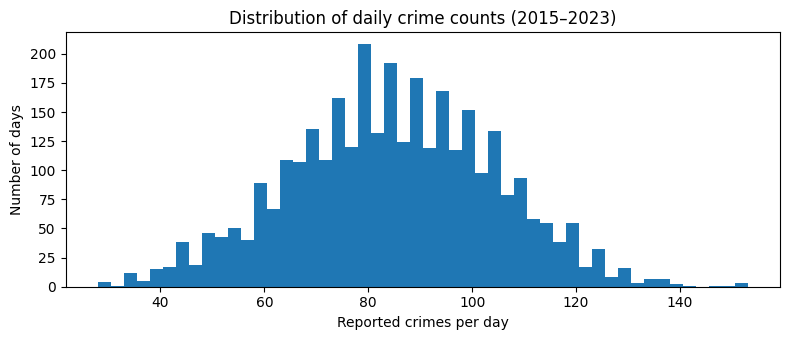

Mean 84.4, variance 390.5, variance/mean = 4.6 (1 would fit a Poisson model)
Skew: -0.01 (raw counts) vs. -0.72 (log counts)
75th percentile: 98 crimes


In [ ]:
daily_explore = explore.groupby("date").size().reindex(pd.date_range(START, DEV_END), fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(daily_explore, bins=50, color="tab:blue")
ax.set_xlabel("Reported crimes per day"); ax.set_ylabel("Number of days")
ax.set_title("Distribution of daily crime counts (2015–2023)")
plt.tight_layout(); plt.show()

print(f"Mean {daily_explore.mean():.1f}, variance {daily_explore.var():.1f}, "
      f"variance/mean = {daily_explore.var() / daily_explore.mean():.1f} (1 would fit a Poisson model)")
print(f"Skew: {daily_explore.skew():.2f} (raw counts) vs. {np.log1p(daily_explore).skew():.2f} (log counts)")
print(f"75th percentile: {daily_explore.quantile(0.75):.0f} crimes")

In [ ]:
ratio = daily_explore.var() / daily_explore.mean()
sk, log_sk = daily_explore.skew(), np.log1p(daily_explore).skew()
say("Typical day", f"{daily_explore.median():.0f} crimes; half of all days fall between "
    f"{daily_explore.quantile(0.25):.0f} and {daily_explore.quantile(0.75):.0f}.")
say("Spread", f"the variance is {ratio:.1f}× the mean. " + (
    "Counts are over-dispersed, so a Negative Binomial model fits better than a Poisson model." if ratio > 1.5
    else "This is close to what a Poisson model assumes."))
say("Shape", ("right-skewed" if sk > 0.5 else "left-skewed" if sk < -0.5 else "roughly symmetric") +
    f" (skew {sk:.2f}); after a log transform the skew is {log_sk:.2f}" +
    (", which supports log-transforming the count-based lag features." if abs(log_sk) < abs(sk) else "."))
say("Target threshold", f"the 75th percentile is {daily_explore.quantile(0.75):.0f} crimes on 2015-2023.  "
    "The models use 96 (section 4.3), because 2015 is lost to the lag features and the threshold is recomputed on 2016-2023.")

- Typical day: 84 crimes; half of all days fall between 71 and 98.
- Spread: the variance is 4.6× the mean. Counts are over-dispersed, so a Negative Binomial model fits better than a Poisson model.
- Shape: roughly symmetric (skew -0.01); after a log transform the skew is -0.72.
- Target threshold: the 75th percentile is 98 crimes on 2015-2023.  The models use 96 (section 4.3), because 2015 is lost to the lag features and the threshold is recomputed on 2016-2023.


**Noise: outliers and possible gaps.** Days far outside the usual range (beyond 3 × the interquartile range)
and days with zero reports, which could be gaps in the data rather than truly quiet days.

**Decision:** outlier days are **kept**. They are real reported days, and the target only asks whether a day
is above the 75th percentile, so an extreme day counts as just one high-crime day when models are scored.
During training, the Bayesian Negative Binomial is designed for occasional large counts; the random forest and
neural network are trained on squared error, where extreme days pull harder (a limitation to note).

In [ ]:
q1, q3 = daily_explore.quantile([0.25, 0.75])
low, high = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
outliers = daily_explore[(daily_explore < low) | (daily_explore > high)]
print(f"Outlier rule: fewer than {low:.0f} or more than {high:.0f} crimes in a day -> {len(outliers)} days")
print(outliers.rename("crimes").to_string() if len(outliers) else "None")
print(f"\nDays with zero reports: {(daily_explore == 0).sum()}")

Outlier rule: fewer than -10 or more than 179 crimes in a day -> 0 days
None

Days with zero reports: 0


In [ ]:
hi_out, lo_out = outliers[outliers > high], outliers[outliers < low]
detail = []
if len(hi_out):
    detail.append(f"{len(hi_out)} unusually busy (highest: {hi_out.idxmax().date()}, {hi_out.max()} crimes)")
if len(lo_out):
    detail.append(f"{len(lo_out)} unusually quiet (lowest: {lo_out.idxmin().date()}, {lo_out.min()} crimes)")
say("Outliers", f"{len(outliers)} day{'s' if len(outliers) != 1 else ''} ({len(outliers) / len(daily_explore):.2%} "
    "of days) fall outside the 3 × IQR range" + (": " + "; ".join(detail) + "." if detail else "."))
n_zero = (daily_explore == 0).sum()
say("Gaps", "no day has zero reports, so there is no sign of missing days in the data." if n_zero == 0
    else f"{n_zero} days have zero reports; these may be gaps in the data rather than quiet days.")

- Outliers: 0 days (0.00% of days) fall outside the 3 × IQR range.
- Gaps: no day has zero reports, so there is no sign of missing days in the data.


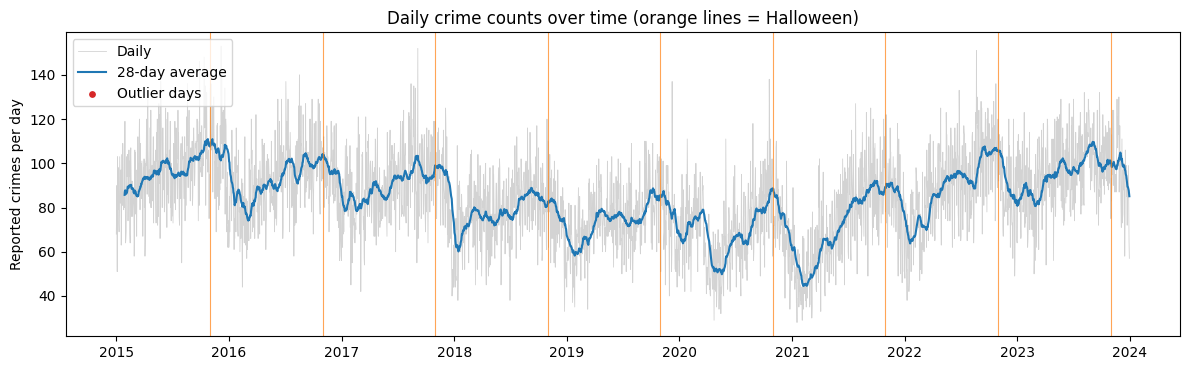

In [ ]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily_explore.index, daily_explore.values, color="lightgrey", linewidth=0.6, label="Daily")
ax.plot(daily_explore.index, daily_explore.rolling(28).mean(), color="tab:blue", label="28-day average")
ax.scatter(outliers.index, outliers.values, color="tab:red", s=15, zorder=3, label="Outlier days")
for y in range(2015, 2024):
    ax.axvline(pd.Timestamp(f"{y}-10-31"), color="tab:orange", linewidth=0.8, alpha=0.7)
ax.set_ylabel("Reported crimes per day"); ax.legend(loc="upper left")
ax.set_title("Daily crime counts over time (orange lines = Halloween)")
plt.tight_layout(); plt.show()

In [ ]:
yearly = daily_explore.groupby(daily_explore.index.year).mean()
print("Average crimes per day by year:")
print(yearly.round(1).to_string())
say("Trend", f"the busiest year was {yearly.idxmax()} ({yearly.max():.1f}/day) and the quietest {yearly.idxmin()} "
    f"({yearly.min():.1f}/day); from {yearly.index[0]} to {yearly.index[-1]} the level changed by "
    f"{(yearly.iloc[-1] / yearly.iloc[0] - 1) * 100:+.0f}%. " +
    ("The yearly level varies noticeably, lag features are tested in section 6 to see whether they help follow it."
     if (yearly.max() - yearly.min()) / yearly.mean() > 0.10 else
     "The yearly level is fairly stable."))
if 2019 in yearly and 2020 in yearly:
    say("COVID", f"2020 averaged {(yearly[2020] / yearly[2019] - 1) * 100:+.0f}% vs. 2019; "
        "the COVID flag lets the models account for that period.")

Average crimes per day by year:
2015    97.6
2016    92.2
2017    89.5
2018    77.8
2019    74.4
2020    69.6
2021    73.5
2022    89.4
2023    95.8
- Trend: the busiest year was 2015 (97.6/day) and the quietest 2020 (69.6/day); from 2015 to 2023 the level changed by -2%. The yearly level varies noticeably, lag features are tested in section 6 to see whether they help follow it.
- COVID: 2020 averaged -6% vs. 2019; the COVID flag lets the models account for that period.


### 3.3 Calendar patterns

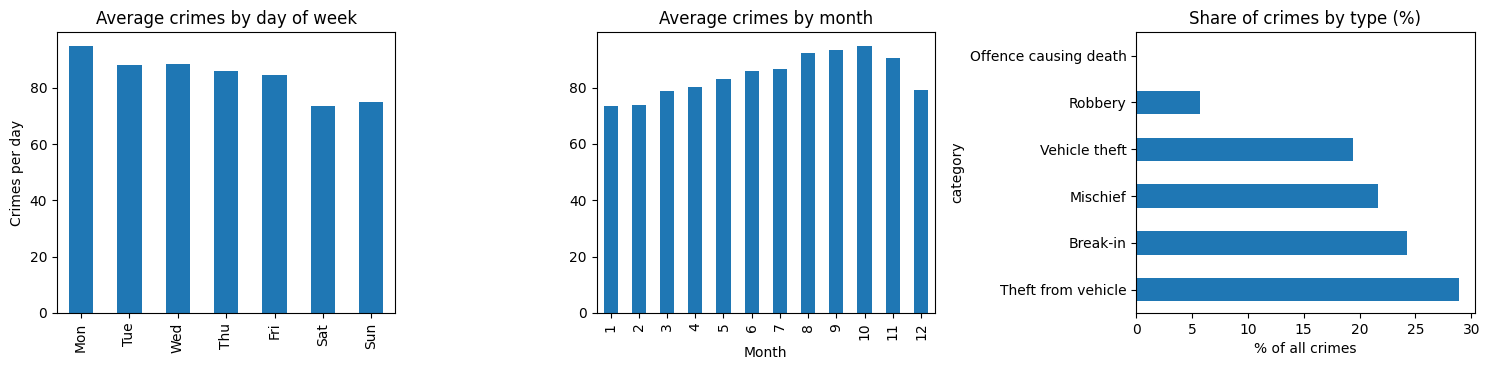

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
daily_explore.groupby(daily_explore.index.dayofweek).mean().set_axis(dow_names).plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_title("Average crimes by day of week"); axes[0].set_ylabel("Crimes per day"); axes[0].set_xlabel("")

daily_explore.groupby(daily_explore.index.month).mean().plot.bar(ax=axes[1], color="tab:blue")
axes[1].set_title("Average crimes by month"); axes[1].set_xlabel("Month")

explore["category"].value_counts(normalize=True).mul(100).plot.barh(ax=axes[2], color="tab:blue")
axes[2].set_title("Share of crimes by type (%)"); axes[2].set_xlabel("% of all crimes")
plt.tight_layout(); plt.show()

In [ ]:
by_dow = daily_explore.groupby(daily_explore.index.dayofweek).mean()
by_month = daily_explore.groupby(daily_explore.index.month).mean()
avg = daily_explore.mean()
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
say("Day of week", f"busiest is {dow_names[by_dow.idxmax()]} ({(by_dow.max() / avg - 1) * 100:+.0f}% vs. average), "
    f"quietest is {dow_names[by_dow.idxmin()]} ({(by_dow.min() / avg - 1) * 100:+.0f}%), so day of week is a feature.")
say("Season", f"busiest month is {month_names[by_month.idxmax() - 1]} ({(by_month.max() / avg - 1) * 100:+.0f}%), "
    f"quietest is {month_names[by_month.idxmin() - 1]} ({(by_month.min() / avg - 1) * 100:+.0f}%), "
    "so smooth seasonal features (sine/cosine of the day of year) are included.")

- Day of week: busiest is Mon (+13% vs. average), quietest is Sat (-13%), so day of week is a feature.
- Season: busiest month is Oct (+12%), quietest is Jan (-13%), so smooth seasonal features (sine/cosine of the day of year) are included.


### 3.4 What happens around Halloween?
Average daily crimes by type for each day from 14 days before to 7 days after Oct 31, relative to that type's
average in the same period (100 = normal).

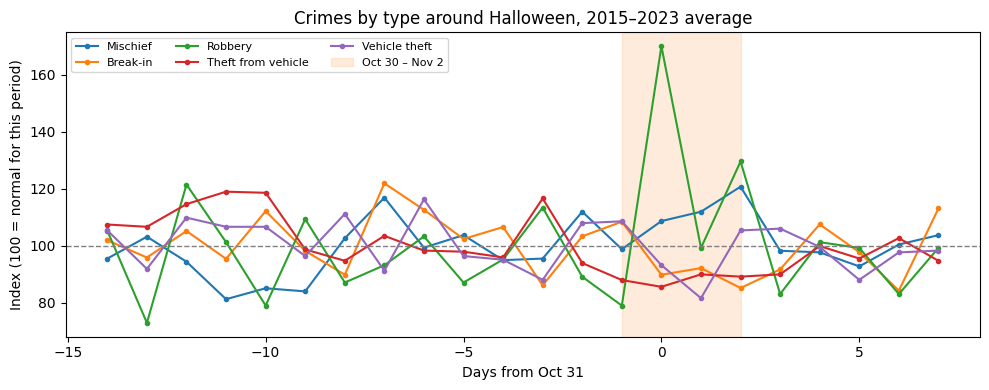

In [ ]:
cat_daily = (explore.groupby(["date", "category"]).size().unstack(fill_value=0)
                    .reindex(pd.date_range(START, DEV_END), fill_value=0))
h = (cat_daily.index - pd.to_datetime(cat_daily.index.year.astype(str) + "-10-31")).days
around = cat_daily[(h >= -14) & (h <= 7)].groupby(h[(h >= -14) & (h <= 7)]).mean()
relative = around / around.mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
for c in ["Mischief", "Break-in", "Robbery", "Theft from vehicle", "Vehicle theft"]:
    ax.plot(relative.index, relative[c], marker="o", ms=3, label=c)
ax.axvspan(-1, 2, color="tab:orange", alpha=0.15, label="Oct 30 – Nov 2")
ax.axhline(100, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Days from Oct 31"); ax.set_ylabel("Index (100 = normal for this period)")
ax.set_title("Crimes by type around Halloween, 2015–2023 average")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

In [ ]:
window_index = relative.loc[-1:2].mean()
say("Around Halloween (descriptive)", "average level on Oct 30 – Nov 2 relative to the surrounding weeks: " +
    ", ".join(f"{c} {window_index[c]:.0f}" for c in ["Mischief", "Break-in", "Robbery", "Theft from vehicle", "Vehicle theft"])
    + " (100 = normal). This is a raw average with no controls; the models in section 10 test it properly.")

- Around Halloween (descriptive): average level on Oct 30 – Nov 2 relative to the surrounding weeks: Mischief 110, Break-in 94, Robbery 119, Theft from vehicle 88, Vehicle theft 97 (100 = normal). This is a raw average with no controls; the models in section 10 test it properly.


### 3.5 Correlations between attributes
Daily counts by crime type and by time of day: which series move together? (Correlations with the engineered
features are in section 4.3.)

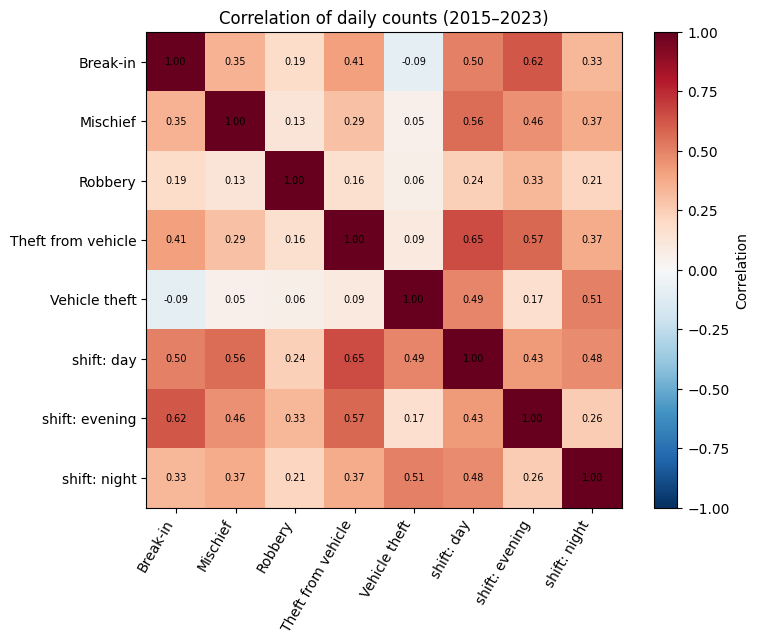

In [ ]:
shift_daily = (explore.groupby(["date", "shift"]).size().unstack(fill_value=0)
                      .reindex(pd.date_range(START, DEV_END), fill_value=0).add_prefix("shift: "))
corr = cat_daily.drop(columns="Offence causing death", errors="ignore").join(shift_daily).corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation of daily counts (2015–2023)")
plt.tight_layout(); plt.show()

In [ ]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().sort_values()
strong = pairs.tail(3)[::-1]
say("Strongest correlations", "; ".join(f"{a} & {b} ({v:.2f})" for (a, b), v in strong.items()) + ".")
say("Weakest correlation", f"{pairs.index[0][0]} & {pairs.index[0][1]} ({pairs.iloc[0]:.2f}). "
    "Crime types that move together share common drivers (season, weekday); weakly linked types need their own models, "
    "which is why section 10 also models each crime type separately.")

- Strongest correlations: Theft from vehicle & shift: day (0.65); Break-in & shift: evening (0.62); Theft from vehicle & shift: evening (0.57).
- Weakest correlation: Break-in & Vehicle theft (-0.09). Crime types that move together share common drivers (season, weekday); weakly linked types need their own models, which is why section 10 also models each crime type separately.


### 3.6 Promising transformations and extra data

**Transformations used in section 4:**
- Aggregate individual reports into **daily counts** (one row per day, including days with zero reports).
- Decompose the date into **day of week**, **cyclical day of year** (sine/cosine, so Dec 31 and Jan 1 are close), holidays, a COVID period flag and Halloween flags.
- **Lag features** (recent crime level, same period last year), **log-transformed** so that levels are on a relative (percentage) scale, which matches the Negative Binomial's log link. Counts are not skewed (see 3.2)
- **Standardize** numeric features (inside the pipeline).

**Extra data that would be useful** (not in this dataset):
- **Weather** (temperature, rain, snow): outdoor activity and therefore opportunities for crime depend on it, and
  Halloween weather varies a lot from year to year.
- **Event dates** (festivals, sports games, school holidays) and **daylight/sunset times**, which change street activity.
- **Police deployment** on Halloween (extra patrols reduce crime or increase reports, which biases the effect).
- **District boundaries and population** over time, to put merged and closed districts on a common map and
  compute crime rates instead of counts.
- **Other crime types** (assaults, disturbances), which are not in this dataset but may be the ones Halloween affects most.
- **The time the crime happened**, not only when it was reported.

### 3.7 Summary of what we learned
Every summary line printed in sections 3.1–3.5, collected in one place:

In [ ]:
for line in LEARNINGS:
    print("- " + line)

- Data: 277,449 reported crimes in 2015–2023, described by 8 attributes.
- Missing values: x_mtm8 16.9%, y_mtm8 16.9%, longitude 16.9%, latitude 16.9%
- Location noise: 16.9% of rows have coordinates that are missing or outside Montréal. They are set to missing during cleaning, but the rows are kept because they still count as crimes.
- Crime types: very imbalanced: Theft from vehicle is 29% of reports, Offence causing death only 0.09%.
- Districts: 34 district numbers appear; some exist only part of the period (handled in section 4.1).
- Typical day: 84 crimes; half of all days fall between 71 and 98.
- Spread: the variance is 4.6× the mean. Counts are over-dispersed, so a Negative Binomial model fits better than a Poisson model.
- Shape: roughly symmetric (skew -0.01); after a log transform the skew is -0.72.
- Target threshold: the 75th percentile is 98 crimes; days above it are the 'high-crime days' the models predict.
- Outliers: 0 days (0.00% of days) fall outside the 3 × IQR ran

## 4. Prepare the Data

### 4.1 Cleaning
| Step | Reason |
|---|---|
| Drop rows with no police district | Only 8 rows; district is needed for the "where" analysis |
| Coordinates outside the island of Montréal set to missing | They are placeholder or wrong values; rows are kept because they still count as crimes |
| Keep complete years 2015–2025 | 2026 has no Halloween yet (a copy with 2026 is kept for the 2026 forecast only) |
| Flag stable districts (reports in every year) | Closed or merged districts would distort district-level comparisons |
| Days with no reports filled with 0 | The raw data only lists crimes that happened; a missing day means zero crimes |

In [ ]:
df["shift"] = pd.Categorical(df["shift"], categories=["day", "evening", "night"], ordered=True)
df = df.dropna(subset=["police_district"])
df["police_district"] = df["police_district"].astype(int)

mtl_box = df["latitude"].between(45.39, 45.71) & df["longitude"].between(-73.98, -73.47)
df.loc[~mtl_box, ["x_mtm8", "y_mtm8", "longitude", "latitude"]] = np.nan

df_with_2026 = df.copy()                                    # only for the 2026 forecast (section 11)
df = df[(df["date"] >= START) & (df["date"] <= END)].copy()

active_years = df.groupby("police_district")["date"].apply(lambda s: s.dt.year.nunique())
full_period = active_years[active_years == active_years.max()].index
df["district_stable"] = df["police_district"].isin(full_period)
print("Unstable districts:", sorted(set(active_years.index) - set(full_period)))
print(f"Share of incidents in stable districts: {df['district_stable'].mean():.1%}")
print(f"{len(df):,} reported crimes from {df['date'].min().date()} to {df['date'].max().date()}")

Unstable districts: [11, 22, 24, 33, 55]
Share of incidents in stable districts: 94.3%
340,129 reported crimes from 2015-01-01 to 2025-12-31


### 4.2 Daily series and feature engineering

One row per day: the same function builds features for total crime and for each crime type.

**Calendar features** (known in advance for any date):
- `dow`: day of week (one-hot encoded, Monday = reference)
- `doy_sin`, `doy_cos`: smooth seasonality over the year
- `is_holiday`: Québec statutory holiday
- `covid`: March 15, 2020 – June 30, 2021
- `halloween_window`: **Oct 30 – Nov 2**. Dates are report dates, and Halloween-night incidents are often reported the next morning or later.
- `halloween_weekend`: a Saturday or Sunday inside the Oct 30 - Nov 2 window ( window × weekend-day interaction)

**Lag features** (only data at least 29 days old, log-transformed for a relative scale; see 3.6):
- `recent_level`: average daily count **29 to 56 days earlier**
- `last_year_level`: average daily count around the **same dates last year** (15-day window)
- `last_year_same_weekday`: count on the **same weekday 52 weeks earlier**

The 29-day gap means the model never uses the days right before the one it predicts, which matches planning
about a month ahead. The lag features replace a straight-line `trend`, which models cannot safely extrapolate.

**Note:** the lag features were tested in section but were dropped because iteration 1 (calendar only) won. The final model and the 10.1(a), 10.2, 10.3 and 10.4 analyses use calendar features only. Lags are used only by the district-day model in 10.1(d) and section 11, which builds on its own.

In [ ]:
GAP = 29
all_days = pd.date_range(START, END, freq="D")

# Daily counts: total, by crime type and by time of day
by_cat = df.groupby(["date", "category"]).size().unstack(fill_value=0).reindex(all_days, fill_value=0)
by_cat.columns = ["n_" + c.lower().replace(" ", "_").replace("-", "_") for c in by_cat.columns]
by_shift = df.groupby(["date", "shift"], observed=False).size().unstack(fill_value=0).reindex(all_days, fill_value=0)
by_shift.columns = ["n_shift_" + str(c) for c in by_shift.columns]
counts = by_cat.join(by_shift)
counts["n_total"] = by_cat.sum(axis=1)

# Calendar features (the same for every series)
calendar = pd.DataFrame({"date": all_days})
d = calendar["date"]
calendar["year"] = d.dt.year
calendar["dow"] = d.dt.dayofweek
calendar["doy_sin"] = np.sin(2 * np.pi * d.dt.dayofyear / 365.25)
calendar["doy_cos"] = np.cos(2 * np.pi * d.dt.dayofyear / 365.25)
qc_holidays = holidays.Canada(subdiv="QC", years=range(2015, 2026))
calendar["is_holiday"] = d.isin(pd.to_datetime(list(qc_holidays.keys()))).astype(int)
calendar["covid"] = d.between("2020-03-15", "2021-06-30").astype(int)
calendar["days_to_halloween"] = (d - pd.to_datetime(d.dt.year.astype(str) + "-10-31")).dt.days
calendar["halloween_window"] = calendar["days_to_halloween"].between(-1, 2).astype(int)
calendar["halloween_weekend"] = calendar["halloween_window"] * (calendar["dow"] >= 5).astype(int)

def build_frame(series):
    """Calendar + lag features for one daily count series. Target column: 'count'."""
    f = calendar.copy()
    f["count"] = series.values
    f["recent_level"]           = np.log1p(f["count"].shift(GAP).rolling(28, min_periods=28).mean())
    f["last_year_level"]        = np.log1p(f["count"].shift(357).rolling(15, min_periods=15).mean())  # days t-371..t-357
    f["last_year_same_weekday"] = np.log1p(f["count"].shift(364))
    # The first year has no "last year", so modelling starts in 2016
    return f.dropna(subset=["recent_level", "last_year_level", "last_year_same_weekday"]).reset_index(drop=True)

data = build_frame(counts["n_total"])
print(f"{len(data):,} days with all features, {data['date'].min().date()} → {data['date'].max().date()}")

3,647 days with all features, 2016-01-07 → 2025-12-31


### 4.3 Train/test separation, target and feature correlations

- **Training (development) years: 2016–2023.** Used for exploration, comparison, tuning and error analysis.
- **Test years: 2024–2025.** Held out until section 9.

**Target:** a high-crime day has more crimes than the 75th percentile of the training years (computed on
training years only). This gives 96, not the 98 shown in 3.2, because 2015 is lost to the lag features and the percentile is computed on 2016-2023

In [ ]:
dev = data[data["date"] <= DEV_END].reset_index(drop=True)
THRESH = dev["count"].quantile(0.75)
data["high_day"] = (data["count"] > THRESH).astype(int)
dev["high_day"]  = (dev["count"] > THRESH).astype(int)

print(f"High-crime day = more than {THRESH:.0f} crimes")
print("Share of high-crime days per year (every year should have both kinds of days):")
share = data.groupby("year")["high_day"].mean()
print(share.round(2).to_string())
if share.between(0.05, 0.95).all():
    print(f"Check passed: every year has between {share.min():.0%} and {share.max():.0%} high-crime days, "
          "so AUC can be computed for every year.")
else:
    print("WARNING: some years have almost only one kind of day; AUC for those years is unreliable.")

High-crime day = more than 96 crimes
Share of high-crime days per year (every year should have both kinds of days):
year
2016    0.41
2017    0.36
2018    0.10
2019    0.08
2020    0.05
2021    0.14
2022    0.37
2023    0.48
2024    0.32
2025    0.15
Check passed: every year has between 5% and 48% high-crime days, so AUC can be computed for every year.


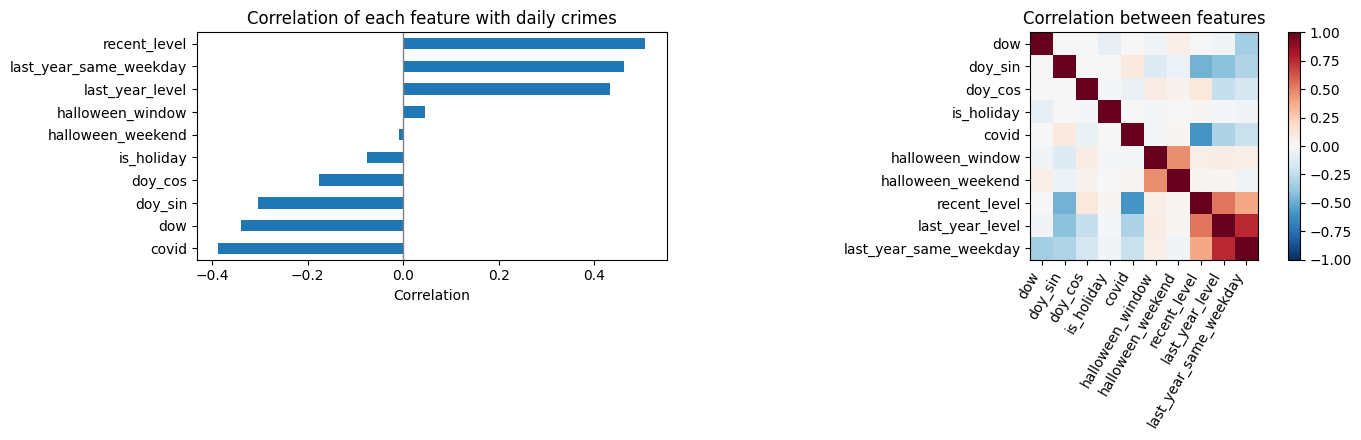

In [ ]:
FEATURE_COLS = ["dow", "doy_sin", "doy_cos", "is_holiday", "covid", "halloween_window", "halloween_weekend",
                "recent_level", "last_year_level", "last_year_same_weekday"]
feat_corr = dev[FEATURE_COLS + ["count"]].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
feat_corr["count"].drop("count").sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].axvline(0, color="grey", linewidth=1)
axes[0].set_title("Correlation of each feature with daily crimes"); axes[0].set_xlabel("Correlation")
im = axes[1].imshow(feat_corr.drop(index="count", columns="count"), cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(FEATURE_COLS))); axes[1].set_xticklabels(FEATURE_COLS, rotation=60, ha="right")
axes[1].set_yticks(range(len(FEATURE_COLS))); axes[1].set_yticklabels(FEATURE_COLS)
axes[1].set_title("Correlation between features"); fig.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

In [ ]:
fc = feat_corr["count"].drop("count")
top3 = fc.abs().sort_values(ascending=False).head(3).index
say("Features most related to daily crimes", ", ".join(f"{f} ({fc[f]:+.2f})" for f in top3) + ".")
say("Halloween flag", f"correlation of halloween_window with daily crimes is {fc['halloween_window']:+.2f}." +
    (" A small value is expected even if Halloween matters: the window is only 4 days a year, so it cannot move "
     "a whole-year correlation much." if abs(fc["halloween_window"]) < 0.1 else ""))
pairs_f = feat_corr.drop(index="count", columns="count")
pairs_f = pairs_f.where(np.triu(np.ones(pairs_f.shape, dtype=bool), k=1)).stack().dropna()
redundant = pairs_f[pairs_f.abs() > 0.8]
say("Redundancy", "no pair of features is highly correlated (|r| > 0.8)." if redundant.empty else
    "highly correlated feature pairs: " + ", ".join(f"{a} & {b} ({v:.2f})" for (a, b), v in redundant.items())
    + "; iteration 3 (feature selection) checks whether one of them can be dropped.")

- Features most related to daily crimes: recent_level (+0.51), last_year_same_weekday (+0.46), last_year_level (+0.43).
- Halloween flag: correlation of halloween_window with daily crimes is +0.05. A small value is expected even if Halloween matters: the window is only 4 days a year, so it cannot move a whole-year correlation much.
- Redundancy: no pair of features is highly correlated (|r| > 0.8).


### 4.4 Sliding-window cross-validation

Each training year from 2019 to 2023 is scored by a model trained only on the **3 years before it**, minus the
last 29 days. This gives **N = 5 folds**; every model uses exactly the same folds. Shuffled K-fold would let a
model train on days after the ones it is tested on, which is leakage for time series.

In [ ]:
TRAIN_YEARS = 3
CV_YEARS = [2019, 2020, 2021, 2022, 2023]

def sliding_folds(frame, test_years, train_years=TRAIN_YEARS, gap=GAP):
    """For each test year: train on the previous `train_years` years, minus the last `gap` days."""
    folds = []
    for ty in test_years:
        cutoff = pd.Timestamp(f"{ty}-01-01") - pd.Timedelta(days=gap)
        train = frame["year"].between(ty - train_years, ty - 1) & (frame["date"] < cutoff)
        test = frame["year"] == ty
        folds.append((np.where(train)[0], np.where(test)[0]))
    return folds

folds = sliding_folds(dev, CV_YEARS)
for ty, (tr, te) in zip(CV_YEARS, folds):
    print(f"Fold {ty}: train {dev.loc[tr, 'date'].min().date()} → {dev.loc[tr, 'date'].max().date()} "
          f"({len(tr)} days), test {len(te)} days")

Fold 2019: train 2016-01-07 → 2018-12-02 (1061 days), test 365 days
Fold 2020: train 2017-01-01 → 2019-12-02 (1066 days), test 366 days
Fold 2021: train 2018-01-01 → 2020-12-02 (1067 days), test 365 days
Fold 2022: train 2019-01-01 → 2021-12-02 (1067 days), test 365 days
Fold 2023: train 2020-01-01 → 2022-12-02 (1067 days), test 365 days


### 4.5 Automated, leak-free pipeline

All preprocessing (one-hot encoding, scaling) sits **inside** a scikit-learn pipeline, so it is re-fitted on the
training part of each fold only. The pipeline takes a **feature set** as input, which lets section 6 compare
feature iterations without changing any other code.

In [ ]:
CAT  = ["dow"]                                                              # one-hot encoded
NUM  = ["doy_sin", "doy_cos", "recent_level", "last_year_level", "last_year_same_weekday"]   # standardized
FLAG = ["is_holiday", "covid", "halloween_window", "halloween_weekend"]    # 0/1, passed through
CALENDAR = ["dow", "doy_sin", "doy_cos", "is_holiday", "covid", "halloween_window", "halloween_weekend"]
LAGS     = ["recent_level", "last_year_level", "last_year_same_weekday"]
ALL_FEATURES = CALENDAR + LAGS
HALLOWEEN = ["halloween_window", "halloween_weekend"]                       # never removed: they are the question

def make_prep(features):
    """Preprocessing for a given feature set; columns not in the set are dropped."""
    return ColumnTransformer([
        ("cat",  OneHotEncoder(drop="first", sparse_output=False), [c for c in CAT if c in features]),
        ("num",  StandardScaler(), [c for c in NUM if c in features]),
        ("flag", "passthrough", [c for c in FLAG if c in features]),
    ])

X_dev, y_dev, label_dev = dev[ALL_FEATURES], dev["count"], dev["high_day"]

def rank_average(score_list):
    """Combine scores on different scales (probabilities, counts) by averaging their percentile ranks."""
    return np.mean([pd.Series(np.asarray(s)).rank(pct=True).values for s in score_list], axis=0)

def auc_from_counts(estimator, X, y):
    """Scorer for count models: a higher predicted count = a higher score for 'high-crime day'."""
    return roc_auc_score(y > THRESH, estimator.predict(X))

def model_score(model, kind, X):
    """Probability for the classifier, predicted count for the count models."""
    return model.predict_proba(X)[:, 1] if kind == "class" else model.predict(X)

def backtest(model, kind, frame=dev, folds=folds):
    """AUC per fold, out-of-fold scores, and the model fitted on the last fold."""
    X, y_count = frame[ALL_FEATURES], frame["count"]
    label = (y_count > THRESH).astype(int)
    scores, oof = [], pd.Series(np.nan, index=frame.index)
    for tr, te in folds:
        m = clone(model)
        m.fit(X.iloc[tr], label.iloc[tr] if kind == "class" else y_count.iloc[tr])
        s = model_score(m, kind, X.iloc[te])
        oof.iloc[te] = s
        scores.append(roc_auc_score(label.iloc[te], s))
    return np.array(scores), oof, m

def summarize(results):
    t = pd.DataFrame(results, index=[f"AUC {y}" for y in CV_YEARS]).T
    per_fold = list(t.columns)
    t.insert(0, "AUC std", t[per_fold].std(axis=1, ddof=0))
    t.insert(0, "AUC mean", t[per_fold].mean(axis=1))
    return t.sort_values("AUC mean", ascending=False).round(3)

## 5. Baseline

**Seasonal naive:** "a day will be busy if the same period last year was busy", using `last_year_level`
directly, with no model. Every model should beat it.

In [ ]:
base_scores = np.array([roc_auc_score(label_dev.iloc[te], dev["last_year_level"].iloc[te]) for _, te in folds])
print(f"Baseline AUC per fold {base_scores.round(3)} | mean {base_scores.mean():.3f} ± {base_scores.std():.3f}")

Baseline AUC per fold [0.685 0.696 0.678 0.763 0.621] | mean 0.688 ± 0.045


## 6. Shortlist Promising Models

### 6.1 The four model families

| Model | Family | Predicts | Why it's included |
|---|---|---|---|
| Logistic regression | Linear classifier | Probability of a high-crime day | Natural fit for a yes/no question; interpretable odds ratios; also used at crime and district level |
| Bayesian Negative Binomial | Bayesian count regression | Daily number of crimes | Handles over-dispersed counts (variance ≫ mean, see 3.2); gives Halloween effects with uncertainty |
| Random forest | Tree ensemble | Daily number of crimes | Captures non-linear patterns and interactions without specifying them |
| Neural network (MLP) | Neural net | Daily number of crimes | Most flexible family; tests whether extra flexibility helps |

The Bayesian model is written in PyMC and wrapped so it works like a scikit-learn model (`fit` / `predict`).
Its prediction is the average over all posterior draws.

In [ ]:
class BayesianNegBin(BaseEstimator, RegressorMixin):
    """Negative Binomial regression fitted with PyMC, usable like a scikit-learn model."""
    def __init__(self, features=tuple(ALL_FEATURES), prior_sigma=0.5, draws=500, tune=500, chains=4, random_seed=SEED):
        self.features, self.prior_sigma = features, prior_sigma
        self.draws, self.tune, self.chains, self.random_seed = draws, tune, chains, random_seed

    def fit(self, X, y):
        self.prep_ = make_prep(self.features).fit(X)
        Z = self.prep_.transform(X).astype(float)
        y = np.asarray(y)
        with pm.Model():
            b0    = pm.Normal("intercept", mu=np.log(y.mean() + 0.5), sigma=1)
            beta  = pm.Normal("beta", mu=0, sigma=self.prior_sigma, shape=Z.shape[1])
            alpha = pm.Exponential("alpha", 0.1)                   # how spread out daily counts are
            pm.NegativeBinomial("y", mu=pm.math.exp(b0 + pm.math.dot(Z, beta)), alpha=alpha, observed=y)
            self.idata_ = pm.sample(draws=self.draws, tune=self.tune, chains=self.chains,
                                    target_accept=0.9, random_seed=self.random_seed, progressbar=False)
        post = self.idata_.posterior
        self.b0_   = post["intercept"].values.ravel()
        self.beta_ = post["beta"].values.reshape(-1, Z.shape[1])
        self.feature_names_ = list(self.prep_.get_feature_names_out())
        return self

    def predict(self, X):
        Z = self.prep_.transform(X).astype(float)
        return np.exp(self.b0_[:, None] + self.beta_ @ Z.T).mean(axis=0)   # average over posterior draws

    def effect(self, feature):
        """% change in expected crimes when a 0/1 feature is on, with a 94% credible interval."""
        pct = (np.exp(self.beta_[:, self.feature_names_.index("flag__" + feature)]) - 1) * 100
        lo, hi = np.percentile(pct, [3, 97])
        return {"effect_%": np.median(pct), "low_94%": lo, "high_94%": hi, "P(increase)": (pct > 0).mean()}

MODEL_NAMES = ["Logistic regression", "Bayesian NegBin", "Random forest", "Neural network"]
KIND = {"Logistic regression": "class", "Bayesian NegBin": "count", "Random forest": "count", "Neural network": "count"}

def make_model(name, features):
    """Each model with standard (default) parameters, on a given feature set."""
    if name == "Logistic regression":
        return Pipeline([("prep", make_prep(features)), ("model", LogisticRegression(max_iter=2000, random_state=SEED))])
    if name == "Bayesian NegBin":
        return BayesianNegBin(features=tuple(features), draws=QUICK_DRAWS, tune=QUICK_DRAWS, chains=2)
    if name == "Random forest":
        return Pipeline([("prep", make_prep(features)), ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))])
    if name == "Neural network":
        return TransformedTargetRegressor(   # target standardized for training, converted back automatically
            regressor=Pipeline([("prep", make_prep(features)), ("model", MLPRegressor(max_iter=2000, random_state=SEED))]),
            transformer=StandardScaler())

### 6.2 How each iteration is run and analysed

Every iteration follows the same steps for all four models, using **standard (default) parameters**:
1. **Train and score** with the 5-fold sliding-window CV (mean ± std AUC)
2. **Most significant variables:** permutation importance on the last fold (2023), i.e. how much AUC drops when
   one feature is randomly shuffled. The same method for every model, so rankings are comparable.
3. **Types of errors:** each model's scores are turned into a yes/no prediction by flagging the **top 25% of days
   in each year** (the same share as the target). Then: miss rate (high-crime days not flagged), false-alarm rate
   (flagged days that were normal), AUC by season and weekday vs. weekend, share of Halloween-window days flagged,
   missed high-crime days by month, and the **correlation of errors between models** (lower = the models make
   different mistakes, which helps an ensemble).

**Iterations:**
- **Iteration 1:** calendar features only
- **Iteration 2:** feature engineering, adding the lag features
- **Iteration 3:** feature selection, removing features that did not help any model in iteration 2

**Limitation:** Permutation importance is computed on the last fold only (2023), which is the year every model did worst (AUC about 0.61–0.70, against roughly 0.75–0.88 in other years). Feature rankings, and the feature-selection rule in iteration 3, may therefore reflect 2023-specific patterns rather than the full period. Averaging importance across all five folds would be more robust (we did not do this because of run time).

In [2]:
SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
          6: "summer", 7: "summer", 8: "summer", 9: "fall", 10: "fall", 11: "fall"}
cv_rows = dev.index[dev["year"].isin(CV_YEARS)]
ev = dev.loc[cv_rows, ["date", "year", "high_day", "halloween_window"]].copy()
ev["season"] = ev["date"].dt.month.map(SEASON)
ev["weekend"] = ev["date"].dt.dayofweek >= 5

def safe_auc(y, s):
    return roc_auc_score(y, s) if y.nunique() == 2 else np.nan

iterations = {}   # label -> results of that iteration

def run_iteration(label, features):
    """Steps 1–3 for all four models on one feature set."""
    res = {"features": list(features), "scores": {"Baseline (seasonal naive)": base_scores}, "oof": {}, "last": {}}
    for name in MODEL_NAMES:
        print(f"{label}: {name} ...")
        res["scores"][name], res["oof"][name], res["last"][name] = backtest(make_model(name, features), KIND[name])

    # Step 2: permutation importance on the last fold
    tr, te = folds[-1]
    imp = {}
    for name in MODEL_NAMES:
        y_eval = label_dev.iloc[te] if KIND[name] == "class" else y_dev.iloc[te]
        r = permutation_importance(res["last"][name], X_dev.iloc[te], y_eval,
                                   scoring="roc_auc" if KIND[name] == "class" else auc_from_counts,
                                   n_repeats=10, random_state=SEED)
        imp[name] = pd.Series(r.importances_mean, index=ALL_FEATURES)
    res["importance"] = pd.DataFrame(imp).loc[list(features)]

    # Step 3: types of errors
    rows, errors, misses = [], {}, {}
    for name in MODEL_NAMES:
        pct = res["oof"][name].loc[cv_rows].groupby(ev["year"]).rank(pct=True)
        flagged = pct > 0.75
        errors[name] = ev["high_day"] - pct                  # positive = under-scored, negative = over-scored
        misses[name] = ((ev["high_day"] == 1) & ~flagged).groupby(ev["date"].dt.month).sum()
        row = {"model": name,
               "miss rate": ((ev["high_day"] == 1) & ~flagged).sum() / (ev["high_day"] == 1).sum(),
               "false alarm rate": ((ev["high_day"] == 0) & flagged).sum() / flagged.sum(),
               "Halloween days flagged": flagged[ev["halloween_window"] == 1].mean()}
        for s in ["winter", "spring", "summer", "fall"]:
            row[f"AUC {s}"] = safe_auc(ev.loc[ev["season"] == s, "high_day"], pct[ev["season"] == s])
        row["AUC weekday"] = safe_auc(ev.loc[~ev["weekend"], "high_day"], pct[~ev["weekend"]])
        row["AUC weekend"] = safe_auc(ev.loc[ev["weekend"], "high_day"], pct[ev["weekend"]])
        rows.append(row)
    res["errors"] = pd.DataFrame(rows).set_index("model").round(3)
    res["misses_by_month"] = pd.DataFrame(misses)
    res["error_corr"] = pd.DataFrame(errors).corr()
    iterations[label] = res
    return res

def show_iteration(label):
    res = iterations[label]
    display(summarize(res["scores"]))

    imp = res["importance"]
    fig, axes = plt.subplots(1, 4, figsize=(18, 0.35 * len(imp) + 1.8), sharey=True)
    order = imp.mean(axis=1).sort_values().index
    for ax, name in zip(axes, MODEL_NAMES):
        ax.barh(order, imp.loc[order, name], color="tab:blue")
        ax.axvline(0, color="grey", linewidth=1)
        ax.set_title(name); ax.set_xlabel("Drop in AUC when shuffled")
    fig.suptitle(f"{label}: permutation importance (2023 fold)"); plt.tight_layout(); plt.show()

    display(res["errors"])
    res["misses_by_month"].plot.bar(figsize=(11, 3.5), width=0.8)
    plt.xlabel("Month"); plt.ylabel("Missed high-crime days (2019–2023)")
    plt.title(f"{label}: where do the models miss high-crime days?"); plt.tight_layout(); plt.show()
    print("Correlation of errors between models (lower = more different mistakes):")
    display(res["error_corr"].round(2))


NameError: name 'dev' is not defined

### 6.3 Iteration 1: calendar features only

Iteration 1 (calendar): Logistic regression ...
Iteration 1 (calendar): Bayesian NegBin ...
Iteration 1 (calendar): Random forest ...
Iteration 1 (calendar): Neural network ...


,AUC mean,AUC std,AUC 2019,AUC 2020,AUC 2021,AUC 2022,AUC 2023
Logistic regression,0.807,0.060,0.839,0.806,0.871,0.826,0.695
Neural network,0.804,0.074,0.841,0.777,0.870,0.861,0.672
Bayesian NegBin,0.801,0.067,0.831,0.747,0.877,0.851,0.698
Random forest,0.745,0.044,0.732,0.755,0.767,0.804,0.670
Baseline (seasonal naive),0.688,0.045,0.685,0.696,0.678,0.763,0.621


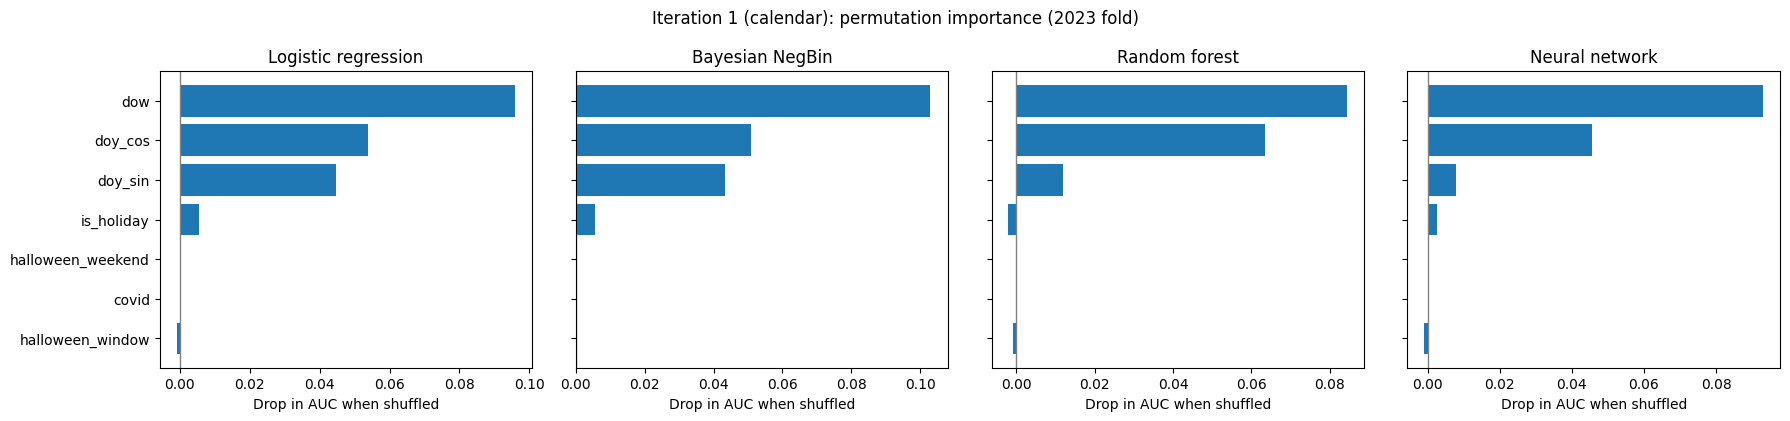

,miss rate,false alarm rate,Halloween days flagged,AUC winter,AUC spring,AUC summer,AUC fall,AUC weekday,AUC weekend
model,,,,,,,,,
Logistic regression,0.501,0.552,0.65,0.665,0.713,0.721,0.675,0.702,0.731
Bayesian NegBin,0.513,0.563,0.65,0.689,0.726,0.723,0.670,0.716,0.686
Random forest,0.591,0.633,0.65,0.535,0.694,0.691,0.615,0.655,0.668
Neural network,0.506,0.557,0.60,0.588,0.796,0.672,0.645,0.712,0.687


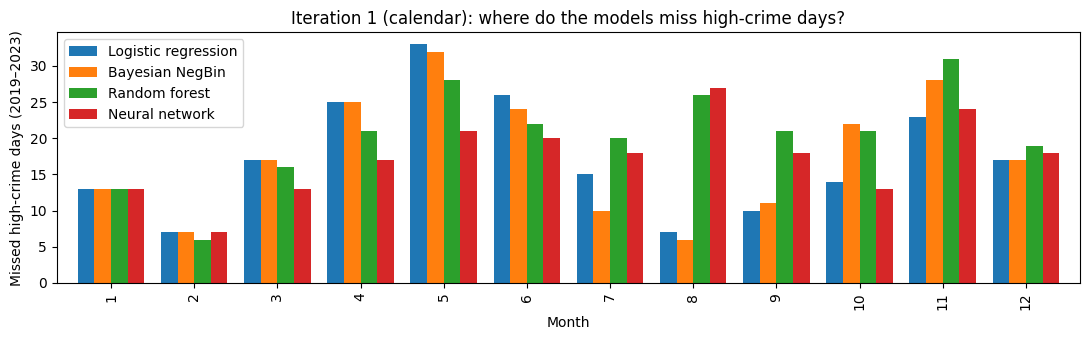

Correlation of errors between models (lower = more different mistakes):


,Logistic regression,Bayesian NegBin,Random forest,Neural network
Logistic regression,1.00,0.98,0.86,0.94
Bayesian NegBin,0.98,1.00,0.86,0.94
Random forest,0.86,0.86,1.00,0.91
Neural network,0.94,0.94,0.91,1.00


In [ ]:
run_iteration("Iteration 1 (calendar)", CALENDAR)
show_iteration("Iteration 1 (calendar)")

**How to read this:** For each model: the table gives the mean and standard deviation of AUC over the 5 folds (higher mean = better, lower std = more stable). The importance charts show which features each model relies on (bars near 0 = not used). The error table shows how often models miss high-crime days or raise false alarms, and in which seasons they do worse. The error-correlation matrix shows whether models make the same mistakes.

**Takeaway:** Calendar structure alone provides a strong predictive signal and establishes the best feature set tested. Logistic regression achieved the highest mean AUC at **0.807**, followed closely by the neural network (**0.804**) and Bayesian Negative Binomial model (**0.802**). All three materially outperformed the seasonal-naive baseline of **0.688**, while the random forest was weaker at **0.745**.

The limited spread among the three leading models suggests that the underlying signal is relatively simple and largely calendar-driven, rather than dependent on highly nonlinear relationships. Day of week and annual seasonality capture much of the predictable variation in crime, while the Halloween indicators contribute comparatively little to overall year-round discrimination.

The remaining errors indicate that calendar information captures recurring patterns but cannot explain unexpected daily shocks. A human planner would likely use additional information on weather, major events, sports games, school schedules, sunset time, public gatherings and police deployment to distinguish between otherwise similar calendar days. At the geographic level, population and neighbourhood activity could further improve prediction.

**Implication:** Calendar variables provide a strong foundation; the remaining error is more likely driven by missing contextual information than by insufficient model complexity.

### 6.4 Iteration 2: feature engineering (adding lag features)

Iteration 2 (+ lags): Logistic regression ...
Iteration 2 (+ lags): Bayesian NegBin ...


ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Iteration 2 (+ lags): Random forest ...
Iteration 2 (+ lags): Neural network ...


,AUC mean,AUC std,AUC 2019,AUC 2020,AUC 2021,AUC 2022,AUC 2023
Bayesian NegBin,0.796,0.062,0.812,0.757,0.870,0.845,0.698
Logistic regression,0.785,0.053,0.805,0.762,0.843,0.823,0.693
Random forest,0.723,0.062,0.654,0.729,0.803,0.778,0.651
Neural network,0.711,0.038,0.701,0.685,0.758,0.749,0.659
Baseline (seasonal naive),0.688,0.045,0.685,0.696,0.678,0.763,0.621


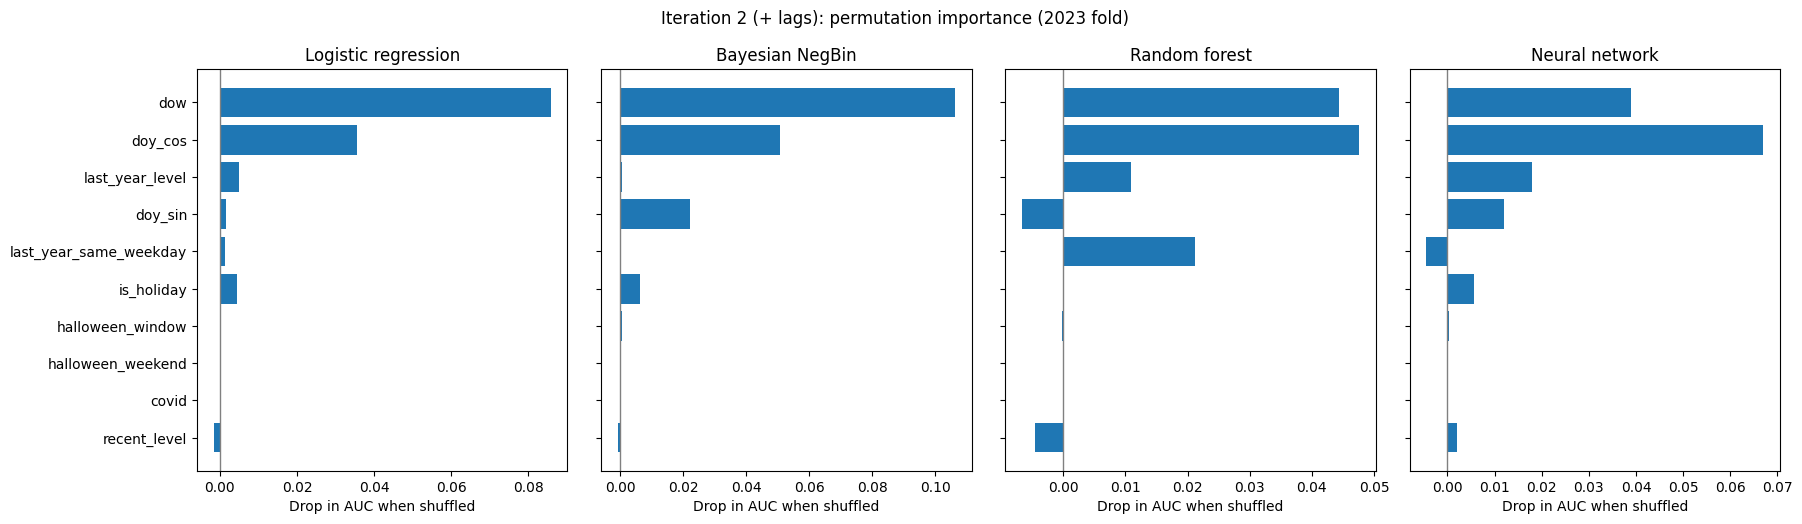

,miss rate,false alarm rate,Halloween days flagged,AUC winter,AUC spring,AUC summer,AUC fall,AUC weekday,AUC weekend
model,,,,,,,,,
Logistic regression,0.528,0.576,0.50,0.590,0.684,0.768,0.643,0.696,0.671
Bayesian NegBin,0.506,0.557,0.60,0.656,0.694,0.778,0.640,0.716,0.650
Random forest,0.576,0.620,0.75,0.466,0.626,0.730,0.598,0.644,0.655
Neural network,0.598,0.639,0.50,0.555,0.568,0.693,0.622,0.639,0.613


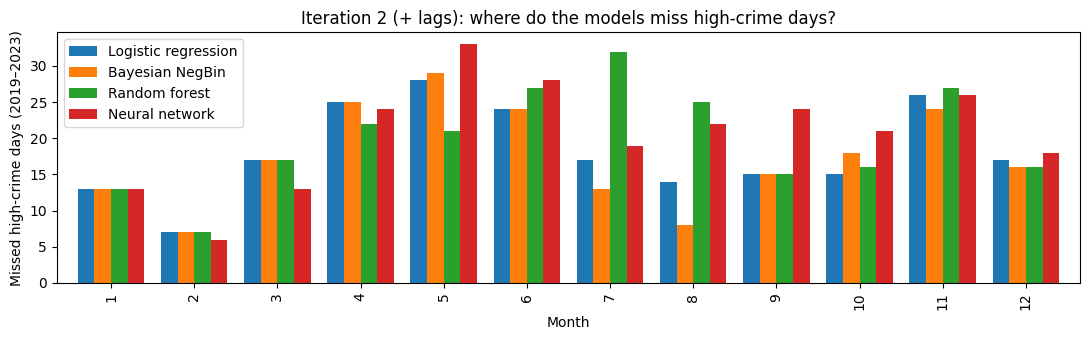

Correlation of errors between models (lower = more different mistakes):


,Logistic regression,Bayesian NegBin,Random forest,Neural network
Logistic regression,1.00,0.98,0.88,0.83
Bayesian NegBin,0.98,1.00,0.89,0.85
Random forest,0.88,0.89,1.00,0.84
Neural network,0.83,0.85,0.84,1.00


In [ ]:
run_iteration("Iteration 2 (+ lags)", ALL_FEATURES)
show_iteration("Iteration 2 (+ lags)")

**How to read this:** Compare each table and chart with iteration 1: a higher AUC means the lag features help; the importance charts show whether the models now rely on them.

**Takeaway:** Adding historical crime lags reduces rather than improves predictive performance, indicating that recent crime levels add limited incremental information once calendar effects are captured.

The Bayesian model declines from **0.802 to 0.797 AUC**, logistic regression from **0.807 to 0.785** and the random forest from **0.745 to 0.723**. The largest deterioration occurs in the neural network, which falls from **0.804 to 0.711**.

This result is important because the lag variables are individually correlated with daily crime, yet they do not improve out-of-sample ranking. In other words, correlation does not translate into incremental predictive value once the model already accounts for day of week and annual seasonality.

The neural network's particularly large decline also suggests that adding weak historical signals increases complexity without introducing stable information.

**Implication:** For this prediction horizon, the simpler calendar-only specification is more robust and generalizable than a richer model incorporating recent crime history.

### 6.5 Iteration 3: feature selection

A feature is removed if shuffling it did **not lower AUC for any of the four models** in iteration 2 (its
permutation importance is ≤ 0 for every model). The Halloween features are always kept, since they are what the
project is about, even if they matter little for overall prediction.

Removed: ['covid']
Iteration 3 (selected): Logistic regression ...
Iteration 3 (selected): Bayesian NegBin ...


ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Iteration 3 (selected): Random forest ...
Iteration 3 (selected): Neural network ...


,AUC mean,AUC std,AUC 2019,AUC 2020,AUC 2021,AUC 2022,AUC 2023
Bayesian NegBin,0.796,0.062,0.812,0.775,0.856,0.850,0.687
Logistic regression,0.784,0.056,0.805,0.762,0.841,0.828,0.686
Random forest,0.728,0.062,0.674,0.728,0.817,0.771,0.648
Neural network,0.692,0.077,0.660,0.676,0.678,0.836,0.608
Baseline (seasonal naive),0.688,0.045,0.685,0.696,0.678,0.763,0.621


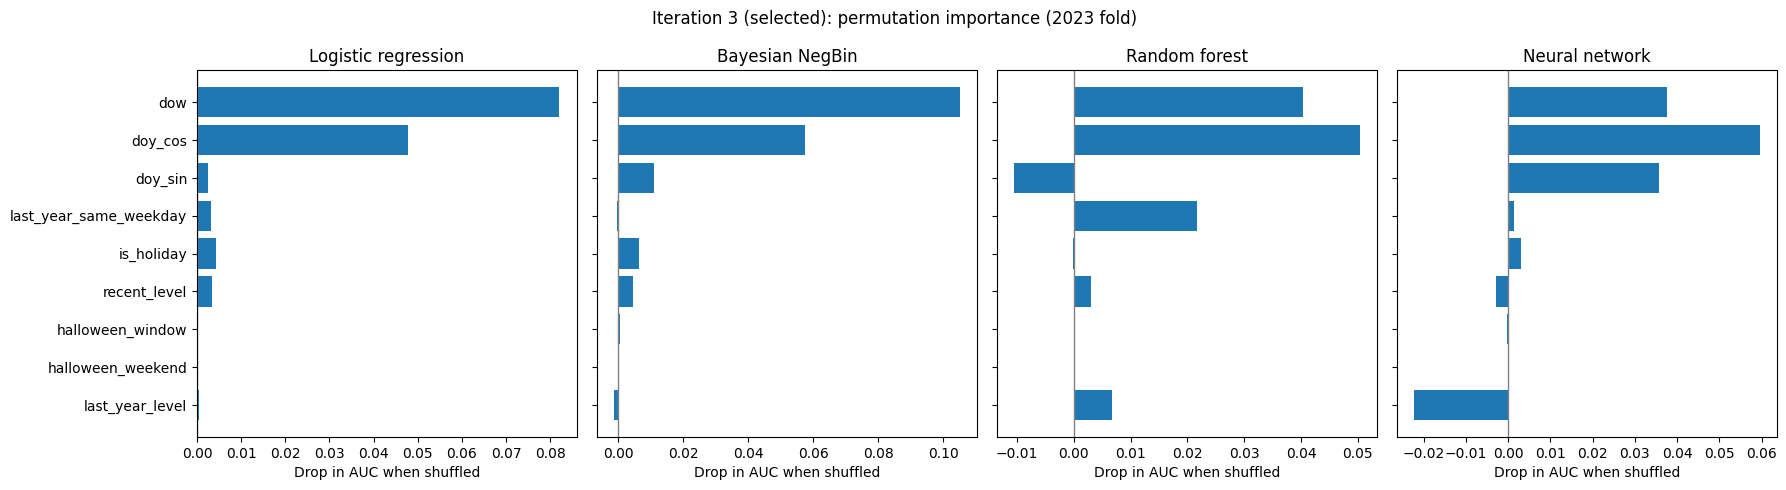

,miss rate,false alarm rate,Halloween days flagged,AUC winter,AUC spring,AUC summer,AUC fall,AUC weekday,AUC weekend
model,,,,,,,,,
Logistic regression,0.530,0.578,0.50,0.593,0.670,0.770,0.642,0.693,0.678
Bayesian NegBin,0.518,0.567,0.60,0.649,0.677,0.774,0.645,0.706,0.681
Random forest,0.574,0.617,0.75,0.501,0.556,0.723,0.608,0.638,0.715
Neural network,0.586,0.628,0.35,0.694,0.416,0.695,0.661,0.634,0.637


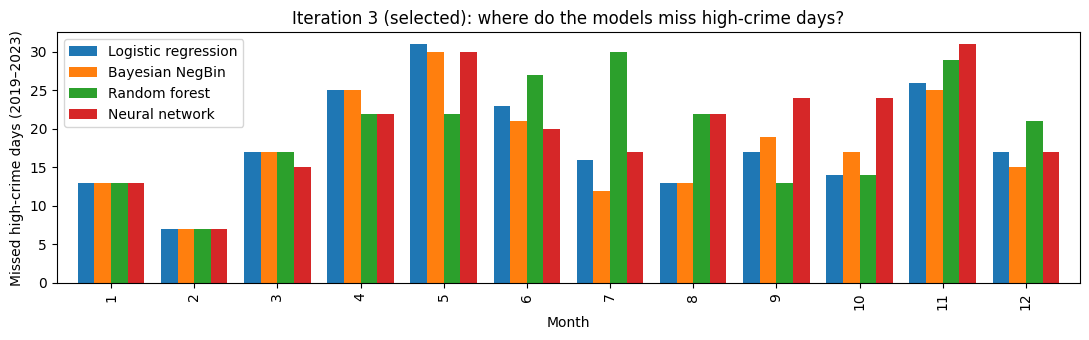

Correlation of errors between models (lower = more different mistakes):


,Logistic regression,Bayesian NegBin,Random forest,Neural network
Logistic regression,1.00,0.98,0.89,0.81
Bayesian NegBin,0.98,1.00,0.88,0.84
Random forest,0.89,0.88,1.00,0.84
Neural network,0.81,0.84,0.84,1.00


In [ ]:
imp2 = iterations["Iteration 2 (+ lags)"]["importance"]
dropped = [f for f in ALL_FEATURES if f not in HALLOWEEN and (imp2.loc[f] <= 0).all()]
SELECTED_IT3 = [f for f in ALL_FEATURES if f not in dropped]
print("Removed:", dropped if dropped else "nothing (every feature helped at least one model)")

if dropped:
    run_iteration("Iteration 3 (selected)", SELECTED_IT3)
    show_iteration("Iteration 3 (selected)")

**How to read this:** If features were removed, compare with iteration 2: a similar or higher AUC means the removed features were not needed. If nothing was removed, every feature helped at least one model.

**Takeaway:** Feature selection does not recover the performance lost when lag variables were introduced. The COVID indicator is the only feature removed and performance remains essentially unchanged for logistic regression (**0.784 AUC**), the Bayesian model (**0.796**) and the random forest (**0.728**).

The neural network deteriorates further to **0.692 AUC** and becomes substantially less stable, including a spring AUC of **0.416**.

Removing the COVID indicator therefore provides no meaningful performance gain. More importantly, the exercise confirms that the issue in Iteration 2 is not one isolated weak feature; the calendar-only specification itself is the cleaner and more effective representation of the problem.

**Implication:** Additional feature engineering does not automatically improve prediction. In this case, the most parsimonious specification also produces the strongest out-of-sample results.

**Note on the Bayesian warnings in iterations 2 and 3:** The message "The effective sample size per chain is smaller than 100" appears because the quick first-round Bayesian models use only 300 draws and 2 chains (`QUICK_DRAWS`), to keep the run time manageable. The Bayesian AUC scores in iterations 2 and 3 should therefore be read as approximate. This does not affect the final conclusions: the full Bayesian fits in §10.2 use more draws and 4 chains, and pass every convergence check (max r_hat = 1.00, no divergences).

### 6.6 Comparing the iterations

The feature set with the highest average CV AUC across the four models is kept for the rest of the notebook.

Iteration 1 (calendar)         Iteration 2 (+ lags)  \
                                        AUC mean AUC std             AUC mean   
Logistic regression                        0.807   0.060                0.785   
Neural network                             0.804   0.074                0.711   
Bayesian NegBin                            0.801   0.067                0.796   
Random forest                              0.745   0.044                0.723   
Baseline (seasonal naive)                  0.688   0.045                0.688   

                                  Iteration 3 (selected)          
                          AUC std               AUC mean AUC std  
Logistic regression         0.053                  0.784   0.056  
Neural network              0.038                  0.692   0.077  
Bayesian NegBin             0.062                  0.796   0.062  
Random forest               0.062                  0.728   0.062  
Baseline (seasonal naive)   0.045                  0.688   0.045

Average AUC across the four models: {'Iteration 1 (calendar)': np.float64(0.789), 'Iteration 2 (+ lags)': np.float64(0.754), 'Iteration 3 (selected)': np.float64(0.75)}
Kept: Iteration 1 (calendar) -> features ['dow', 'doy_sin', 'doy_cos', 'is_holiday', 'covid', 'halloween_window', 'halloween_weekend']


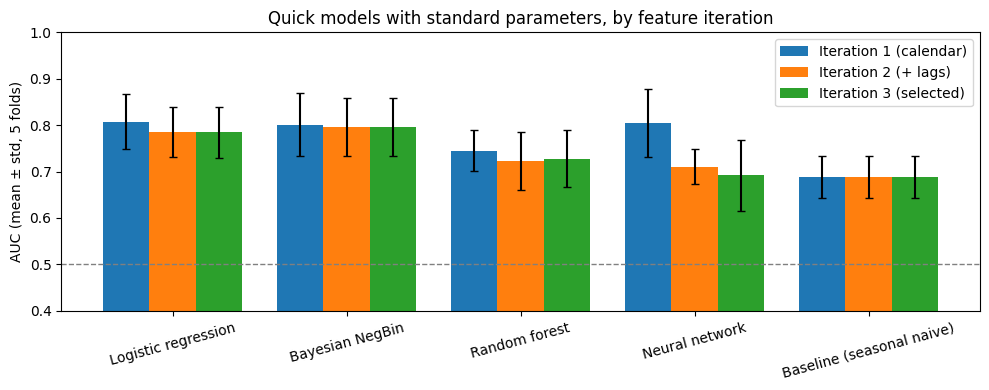

In [ ]:
iteration_table = pd.concat({lab: summarize(r["scores"])[["AUC mean", "AUC std"]] for lab, r in iterations.items()},
                            axis=1)
display(iteration_table)

avg_auc = {lab: np.mean([r["scores"][m].mean() for m in MODEL_NAMES]) for lab, r in iterations.items()}
BEST_IT = max(avg_auc, key=avg_auc.get)
SELECTED_FEATURES = iterations[BEST_IT]["features"]
print("Average AUC across the four models:", {k: round(v, 3) for k, v in avg_auc.items()})
print(f"Kept: {BEST_IT} -> features {SELECTED_FEATURES}")

fig, ax = plt.subplots(figsize=(10, 4))
names = MODEL_NAMES + ["Baseline (seasonal naive)"]
x, w = np.arange(len(names)), 0.8 / len(iterations)
for k, (lab, r) in enumerate(iterations.items()):
    ax.bar(x + (k - (len(iterations) - 1) / 2) * w, [r["scores"][n].mean() for n in names], w,
           yerr=[r["scores"][n].std() for n in names], capsize=3, label=lab)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15)
ax.set_ylim(0.4, 1.0); ax.set_ylabel("AUC (mean ± std, 5 folds)")
ax.set_title("Quick models with standard parameters, by feature iteration"); ax.legend()
plt.tight_layout(); plt.show()

**How to read this:** Each group of bars is one model; each colour is one feature iteration. Error bars show the standard deviation across folds; differences smaller than the error bars are not meaningful. The dashed line (0.5) is a coin flip.

**Takeaway:** Iteration 1 is the clear feature-set winner: calendar-only models achieve the highest average AUC while using the fewest inputs.

Across the four model families, mean AUC is **0.790** with calendar features only, compared with **0.754** after adding lag features and **0.750** after feature selection.

The decline is driven most strongly by the neural network, which falls from **0.804** to **0.711** and then **0.692**. Logistic regression, the Bayesian model and the random forest are less sensitive, but none shows a meaningful improvement over the calendar-only specification.

Although some differences for individual models fall within fold-to-fold variability, there is no evidence that either additional iteration creates a consistent performance gain.

**Decision:** Retain Iteration 1 (calendar features only) for model selection and tuning. It provides the strongest overall discrimination, the simplest interpretation and the lowest unnecessary complexity.

### 6.7 Shortlist

The checklist asks for the most promising models, **preferring models that make different types of errors**. With
four models, every possible shortlist of three is compared on:
- the members' average CV AUC (how good they are on their own)
- the average error correlation between members (how different their mistakes are)
- the CV AUC of their rank-averaged ensemble, which rewards both

The shortlist with the best ensemble AUC is kept.

**How to read this:** each row is one possible shortlist of three. A higher ensemble AUC is better; a lower average error correlation means the members make more different mistakes.

**Reasons for the shortlist (group):** We shortlisted logistic regression, the Bayesian model and the neural network because they can give the highest ensemble AUC of 0.811 together. We left out random forest because it was the weakest model (AUC 0.745 in 6.3) with calendar features. It also makes different mistakes than the other models, but is too weak to improve the ensemble. The difference between the shortlist options is small (0.802) to (0.811) compared to the variation across folds (about +-0.06), so the other combinations would work well.

In [ ]:
best = iterations[BEST_IT]
rows = []
for combo in itertools.combinations(MODEL_NAMES, 3):
    combo = list(combo)
    ens = [roc_auc_score(label_dev.iloc[te], rank_average([best["oof"][m].iloc[te] for m in combo])) for _, te in folds]
    corr = best["error_corr"].loc[combo, combo].values[np.triu_indices(3, 1)].mean()
    rows.append({"shortlist": " + ".join(combo), "left out": [m for m in MODEL_NAMES if m not in combo][0],
                 "members' mean AUC": np.mean([best["scores"][m].mean() for m in combo]),
                 "avg error correlation": corr, "ensemble AUC mean": np.mean(ens), "ensemble AUC std": np.std(ens)})

shortlist_table = pd.DataFrame(rows).sort_values("ensemble AUC mean", ascending=False).round(3).reset_index(drop=True)
SHORTLIST = [m for m in MODEL_NAMES if m != shortlist_table.loc[0, "left out"]]
print("Shortlist:", SHORTLIST)
shortlist_table

Shortlist: ['Logistic regression', 'Bayesian NegBin', 'Neural network']


,shortlist,left out,members' mean AUC,avg error correlation,ensemble AUC mean,ensemble AUC std
0,Logistic regression + Bayesian NegBin + Neural...,Random forest,0.804,0.955,0.811,0.066
1,Logistic regression + Random forest + Neural n...,Bayesian NegBin,0.786,0.904,0.806,0.063
2,Logistic regression + Bayesian NegBin + Random...,Neural network,0.785,0.902,0.805,0.059
3,Bayesian NegBin + Random forest + Neural network,Logistic regression,0.783,0.906,0.802,0.065


## 7. Fine-Tune the System

Each shortlisted model is tuned with **random search** over the same 5 sliding-window folds. Random search is
preferred over grid search because it covers wide ranges with a fixed budget of trials, and most
hyperparameters have little effect, so a grid would waste trials on them.

**Data-transformation choices are treated as hyperparameters:** the numeric scaler (standardize vs. min-max)
is part of the search for the logistic regression and the neural network.

The Bayesian model has only one hyperparameter worth tuning here (the prior width), with few values, so all
values are tried.

| Model | Search space |
|---|---|
| Logistic regression | `C` (regularization, log-uniform 0.001–100), scaler |
| Bayesian NegBin | prior standard deviation of coefficients: 0.25, 0.5, 1.0 |
| Random forest | not tuned (not shortlisted) |
| Neural network | layer sizes, activation, L2 penalty `alpha` (log-uniform), learning rate, scaler |

In [ ]:
SCALERS = [StandardScaler(), MinMaxScaler()]
SEARCH = {
    "Logistic regression": dict(params={"model__C": loguniform(1e-3, 1e2), "prep__num": SCALERS},
                                n_iter=N_ITER, n_jobs=-1),
    "Bayesian NegBin":     dict(params={"prior_sigma": [0.25, 0.5, 1.0]}, n_iter=3, n_jobs=1),
    "Random forest":       dict(params={"model__n_estimators":     [200, 300, 500],
                                        "model__max_depth":        [None, 5, 8, 12],
                                        "model__min_samples_leaf": [1, 5, 10, 20, 40],
                                        "model__max_features":     [1.0, 0.5, "sqrt"]},
                                n_iter=N_ITER, n_jobs=-1),
    "Neural network":      dict(params={"regressor__model__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
                                        "regressor__model__activation":         ["relu", "tanh"],
                                        "regressor__model__alpha":              loguniform(1e-4, 1e1),
                                        "regressor__model__learning_rate_init": [1e-3, 3e-3, 1e-2],
                                        "regressor__prep__num":                 SCALERS},
                                n_iter=N_ITER, n_jobs=-1),
}

def base_model(name):
    m = make_model(name, SELECTED_FEATURES)
    if name == "Bayesian NegBin":
        m.set_params(draws=DRAWS, tune=DRAWS, chains=4)
    return m

TUNED, tuned_results, tuned_oof, best_params = {}, {}, {}, {}
for name in SHORTLIST:
    print(f"Tuning {name} ...")
    spec = SEARCH[name]
    search = RandomizedSearchCV(base_model(name), spec["params"], n_iter=spec["n_iter"], cv=folds,
                                scoring="roc_auc" if KIND[name] == "class" else auc_from_counts,
                                random_state=SEED, n_jobs=spec["n_jobs"], refit=False)
    search.fit(X_dev, label_dev if KIND[name] == "class" else y_dev)
    best_params[name] = search.best_params_
    TUNED[name] = clone(base_model(name)).set_params(**search.best_params_)
    tuned_results[name], tuned_oof[name], _ = backtest(TUNED[name], KIND[name])
    print(f"   best settings: {search.best_params_}")
    print(f"   AUC {tuned_results[name].mean():.3f} ± {tuned_results[name].std():.3f} "
          f"(default: {iterations[BEST_IT]['scores'][name].mean():.3f})")

Tuning Logistic regression ...
   best settings: {'model__C': np.float64(5.596641287183976), 'prep__num': StandardScaler()}
   AUC 0.811 ± 0.060 (default: 0.807)
Tuning Bayesian NegBin ...
   best settings: {'prior_sigma': 0.25}
   AUC 0.805 ± 0.065 (default: 0.801)
Tuning Neural network ...
   best settings: {'regressor__model__activation': 'tanh', 'regressor__model__alpha': np.float64(0.0029381382365341584), 'regressor__model__hidden_layer_sizes': (64,), 'regressor__model__learning_rate_init': 0.001, 'regressor__prep__num': StandardScaler()}
   AUC 0.814 ± 0.069 (default: 0.804)


In [ ]:
tuning_table = pd.DataFrame({
    "default AUC mean": {n: iterations[BEST_IT]["scores"][n].mean() for n in SHORTLIST},
    "tuned AUC mean":   {n: tuned_results[n].mean() for n in SHORTLIST},
    "tuned AUC std":    {n: tuned_results[n].std() for n in SHORTLIST},
}).round(3)
tuning_table

,default AUC mean,tuned AUC mean,tuned AUC std
Logistic regression,0.807,0.811,0.060
Bayesian NegBin,0.801,0.805,0.065
Neural network,0.804,0.814,0.069


**How to read this:** Compares each shortlisted model's CV AUC with default settings vs. after random search. A small gain means the
default settings were already reasonable.

**Takeaway:** Hyperparameter tuning produces incremental rather than transformational gains, confirming that feature choice matters more than model configuration.

Mean AUC improves from **0.807 to 0.811** for logistic regression, **0.802 to 0.804** for the Bayesian Negative Binomial model and **0.804 to 0.814** for the neural network.

The neural network benefits the most and becomes the strongest individual model. However, all improvements remain small relative to the approximately **0.06–0.07 standard deviation across validation years**.

The tuning process selects standard scaling for the models where scaling is tested, while the Bayesian model performs best with a narrower prior of **0.25**.

**Implication:** Tuning improves performance at the margin but does not change the broader conclusion. Predictive performance is driven primarily by the information contained in the feature set rather than aggressive hyperparameter optimization.

## 8. Ensemble

The tuned shortlisted models are combined by averaging their **ranks** within each year (ranks are needed
because probabilities and crime counts are on different scales). The ensemble is scored on the same folds.
The best option overall (a single model or the ensemble) becomes the final model.

In [ ]:
ensemble_scores = np.array([
    roc_auc_score(label_dev.iloc[te], rank_average([tuned_oof[m].iloc[te] for m in SHORTLIST]))
    for _, te in folds])

final_comparison = summarize({**{f"{n} (tuned)": tuned_results[n] for n in SHORTLIST},
                              "Ensemble (tuned shortlist)": ensemble_scores,
                              "Baseline (seasonal naive)": base_scores})
FINAL = final_comparison.index[0]
FINAL_MEMBERS = SHORTLIST if FINAL.startswith("Ensemble") else [FINAL.replace(" (tuned)", "")]
print("Final model:", FINAL)
final_comparison

Final model: Ensemble (tuned shortlist)


,AUC mean,AUC std,AUC 2019,AUC 2020,AUC 2021,AUC 2022,AUC 2023
Ensemble (tuned shortlist),0.815,0.064,0.841,0.797,0.877,0.860,0.699
Neural network (tuned),0.814,0.069,0.846,0.801,0.872,0.866,0.685
Logistic regression (tuned),0.811,0.060,0.847,0.804,0.874,0.827,0.700
Bayesian NegBin (tuned),0.805,0.065,0.833,0.765,0.876,0.852,0.698
Baseline (seasonal naive),0.688,0.045,0.685,0.696,0.678,0.763,0.621


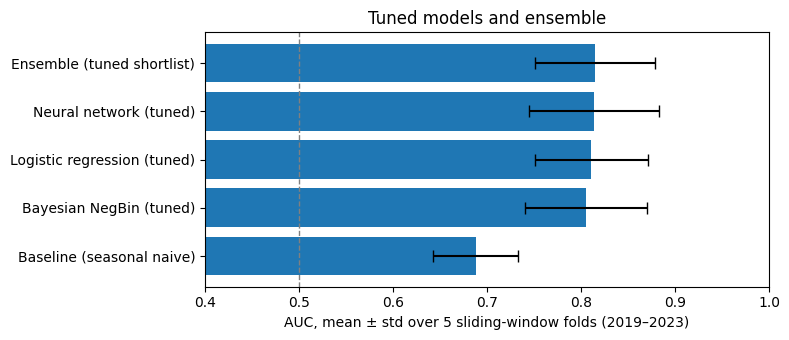

In [ ]:
c = final_comparison.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(c.index, c["AUC mean"], xerr=c["AUC std"], capsize=4, color="tab:blue")
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xlim(0.4, 1.0); ax.set_xlabel("AUC, mean ± std over 5 sliding-window folds (2019–2023)")
ax.set_title("Tuned models and ensemble"); plt.tight_layout(); plt.show()

**How to read this:** Bars show mean CV AUC with standard deviation for each tuned model, the ensemble and the baseline. The top row
of the table is the final model.

**Takeaway:** The tuned ensemble is selected as the final model because it matches the best individual model's accuracy while providing slightly greater stability across years.

Both the ensemble and tuned neural network achieve a mean AUC of **0.814**. However, the ensemble has a slightly lower standard deviation (**0.064 vs. 0.069**) and avoids relying on a single model family.

The tuned logistic regression (**0.811**) and Bayesian Negative Binomial model (**0.804**) also remain competitive and all three individual models materially outperform the seasonal-naive development baseline of **0.688**.

The performance difference between the ensemble and the strongest individual models is small relative to year-to-year variation. Therefore, the rationale for ensembling is robustness, not a material increase in average accuracy.

**Decision:** Use the rank-averaged ensemble of tuned logistic regression, Bayesian Negative Binomial regression and the neural network as the final model.

### 8.1 How much data should the final model use?

The checklist recommends using as much data as possible toward the end of fine-tuning. With time series, older
years may also be less relevant (crime levels and patterns shift). This is treated as a hyperparameter: the final
model is scored on the same 5 folds with two training windows, and the better one is used for the test set.
- **3-year sliding window:** the 3 years before the scored year (used so far)
- **Expanding window:** all earlier years (for 2019 the two are identical; the difference grows each year)

In [ ]:
WINDOWS = {"3-year sliding window": TRAIN_YEARS, "expanding window (all earlier years)": 100}
window_scores = {}
for wname, n_years in WINDOWS.items():
    if n_years == TRAIN_YEARS:   # already computed during tuning
        member_oof = {m: tuned_oof[m] for m in FINAL_MEMBERS}
        w_folds = folds
    else:
        w_folds = sliding_folds(dev, CV_YEARS, train_years=n_years)
        member_oof = {m: backtest(TUNED[m], KIND[m], folds=w_folds)[1] for m in FINAL_MEMBERS}
    window_scores[wname] = np.array([
        roc_auc_score(label_dev.iloc[te], rank_average([member_oof[m].iloc[te] for m in FINAL_MEMBERS]))
        for _, te in w_folds])

window_table = summarize(window_scores)
FINAL_WINDOW = WINDOWS[window_table.index[0]]
print(f"Final model trains on: {window_table.index[0]}")
window_table

Final model trains on: expanding window (all earlier years)


,AUC mean,AUC std,AUC 2019,AUC 2020,AUC 2021,AUC 2022,AUC 2023
expanding window (all earlier years),0.815,0.062,0.841,0.800,0.871,0.863,0.701
3-year sliding window,0.815,0.064,0.841,0.797,0.877,0.860,0.699


**How to read this:** Mean CV AUC of the final model with each training window. If the expanding window wins, older years still
help; if the 3-year window wins, older years are less relevant (patterns have shifted).

**Takeaway:** Using all available prior years is marginally preferable to restricting training to the most recent three years, but the difference is operationally negligible.

The expanding-window approach achieves an AUC of **0.815 ± 0.062**, compared with **0.814 ± 0.064** for the three-year sliding window.

The near-identical performance suggests that older observations neither materially improve nor degrade prediction. This is consistent with the strongest features—day of week and annual seasonality—representing relatively persistent patterns.

**Decision:** Use the expanding window because it retains the maximum available training information. However, the difference is too small to claim that older years provide a meaningful predictive advantage.

## 9. Final model on the held-out test set (run once)

The final model is evaluated on 2024 and 2025 the way it would be used in practice: each year is predicted by
a model trained on the earlier years chosen in 8.1 (minus the 29-day gap). The baseline is evaluated the same way.

**This is the only time the test years are used.** Nothing is changed after this point.

In [ ]:
test_folds = sliding_folds(data, TEST_YEARS, train_years=FINAL_WINDOW)

def fit_score(name, tr, te):
    m = clone(TUNED[name])
    m.fit(data[ALL_FEATURES].iloc[tr], data["high_day"].iloc[tr] if KIND[name] == "class" else data["count"].iloc[tr])
    return m, model_score(m, KIND[name], data[ALL_FEATURES].iloc[te])

final_rows, final_scores, final_fitted = [], pd.Series(np.nan, index=data.index), {}
for ty, (tr, te) in zip(TEST_YEARS, test_folds):
    fitted = {n: fit_score(n, tr, te) for n in FINAL_MEMBERS}
    final_fitted[ty] = {n: f[0] for n, f in fitted.items()}
    s = rank_average([f[1] for f in fitted.values()]) if len(FINAL_MEMBERS) > 1 else fitted[FINAL_MEMBERS[0]][1]
    final_scores.iloc[te] = s
    final_rows.append({"test year": ty,
                       "final model AUC": roc_auc_score(data["high_day"].iloc[te], s),
                       "baseline AUC": roc_auc_score(data["high_day"].iloc[te], data["last_year_level"].iloc[te]),
                       "share of high-crime days": data["high_day"].iloc[te].mean()})

final_test = pd.DataFrame(final_rows).round(3)
print(f"Final model: {FINAL}")
print(f"Cross-validation AUC: {final_comparison.loc[FINAL, 'AUC mean']:.3f} ± {final_comparison.loc[FINAL, 'AUC std']:.3f}")
final_test

Final model: Ensemble (tuned shortlist)
Cross-validation AUC: 0.815 ± 0.064


,test year,final model AUC,baseline AUC,share of high-crime days
0,2024,0.664,0.649,0.320
1,2025,0.674,0.648,0.145


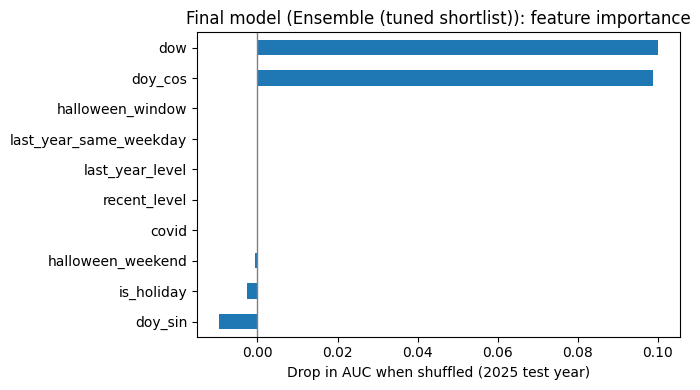

In [ ]:
# Explaining the final model: permutation importance on the 2025 test year
tr, te = test_folds[-1]
imp = {}
for n, m in final_fitted[TEST_YEARS[-1]].items():
    y_eval = data["high_day"].iloc[te] if KIND[n] == "class" else data["count"].iloc[te]
    res = permutation_importance(m, data[ALL_FEATURES].iloc[te], y_eval,
                                 scoring="roc_auc" if KIND[n] == "class" else auc_from_counts,
                                 n_repeats=10, random_state=SEED)
    imp[n] = pd.Series(res.importances_mean, index=ALL_FEATURES)
imp = pd.DataFrame(imp)
imp.mean(axis=1).sort_values().plot.barh(figsize=(7, 4), color="tab:blue")
plt.axvline(0, color="grey", linewidth=1); plt.xlabel("Drop in AUC when shuffled (2025 test year)")
plt.title(f"Final model ({FINAL}): feature importance"); plt.tight_layout(); plt.show()

Days around Halloween in the test years:
      date  count  high_day  days_to_halloween  score_pct
2024-10-28    108         1                 -3       0.96
2024-10-29    104         1                 -2       0.81
2024-10-30     89         0                 -1       0.77
2024-10-31     70         0                  0       0.71
2024-11-01    116         1                  1       0.66
2024-11-02     88         0                  2       0.44
2024-11-03    104         1                  3       0.34
2024-11-04     97         1                  4       0.96
2025-10-28     84         0                 -3       0.80
2025-10-29     78         0                 -2       0.77
2025-10-30     58         0                 -1       0.70
2025-10-31     87         0                  0       0.64
2025-11-01     79         0                  1       0.43
2025-11-02     87         0                  2       0.54
2025-11-03     96         0                  3       0.96
2025-11-04     90         0    

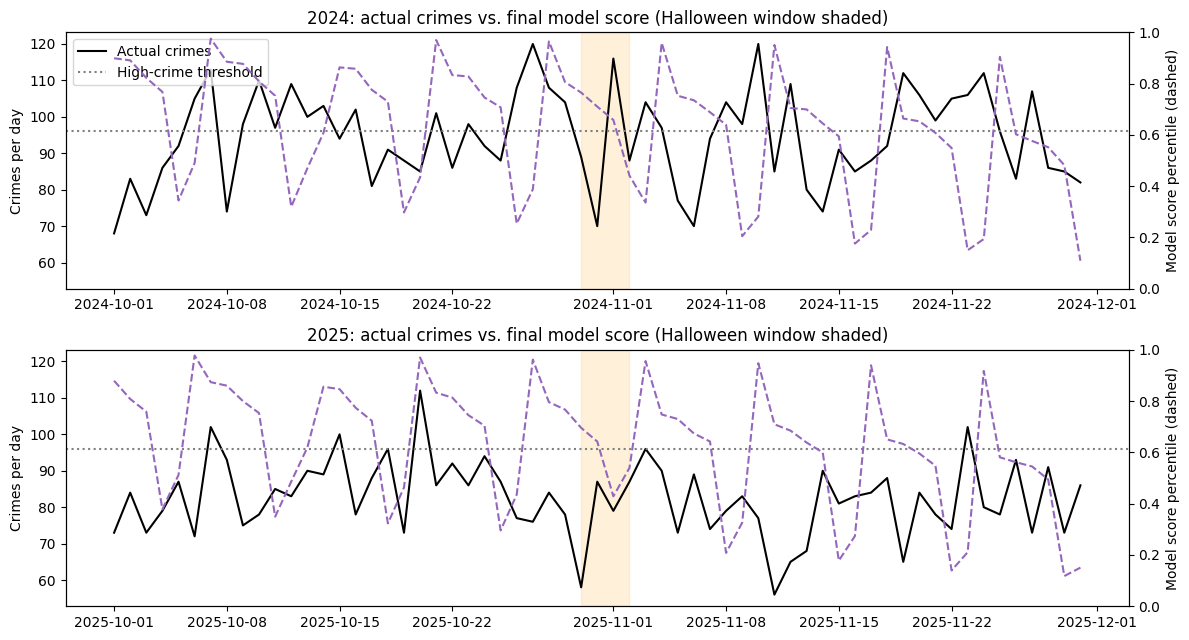

In [ ]:
test_view = data.loc[final_scores.notna(), ["date", "year", "count", "high_day", "days_to_halloween"]].copy()
test_view["score_pct"] = final_scores.dropna().groupby(test_view["year"]).rank(pct=True)
print("Days around Halloween in the test years:")
print(test_view[test_view["days_to_halloween"].between(-3, 4)].drop(columns="year").round(2).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharey=True)
for ax, yr in zip(axes, TEST_YEARS):
    w = test_view[(test_view["date"] >= f"{yr}-10-01") & (test_view["date"] <= f"{yr}-11-30")]
    ax.plot(w["date"], w["count"], color="black", linewidth=1.5, label="Actual crimes")
    ax.axhline(THRESH, color="grey", linestyle=":", label="High-crime threshold")
    ax2 = ax.twinx()
    ax2.plot(w["date"], w["score_pct"], color="tab:purple", linestyle="--")
    ax2.set_ylim(0, 1); ax2.set_ylabel("Model score percentile (dashed)")
    ax.axvspan(pd.Timestamp(f"{yr}-10-30"), pd.Timestamp(f"{yr}-11-02"), color="orange", alpha=0.15)
    ax.set_title(f"{yr}: actual crimes vs. final model score (Halloween window shaded)")
    ax.set_ylabel("Crimes per day")
axes[0].legend(loc="upper left"); plt.tight_layout(); plt.show()

**How to read this:** Black line: actual crimes; dotted line: the high-crime threshold; dashed purple line: the model's score as a
percentile within the year (1.0 = the day the model ranks as most likely to be busy). Good days for the model are
those where the dashed line is high when the black line is above the threshold. Compare the test AUC with the CV AUC:
a similar value means the model generalizes to new years.

**Takeaway:** The final model generalizes to unseen years and continues to outperform the benchmark, but the advantage is materially smaller than development-period cross-validation suggested.

The ensemble achieved a development-period cross-validation AUC of **0.814 ± 0.064**. On the untouched test years, AUC declined to **0.664 in 2024**, compared with **0.649** for the seasonal-naive baseline, and **0.674 in 2025**, compared with **0.648** for the baseline.

The model therefore retains positive incremental predictive value, outperforming the benchmark by **0.015 AUC in 2024** and **0.026 in 2025**. However, the approximately **0.14–0.15 decline from development AUC to test AUC** indicates that historical cross-validation overstates performance on the most recent years.

The target distribution also shifts materially: **32.0% of days in 2024** exceed the fixed high-crime threshold, compared with only **14.5% in 2025**. This highlights the impact of temporal drift when applying a threshold calibrated on historical data.

Around Halloween specifically, high-crime activity is not concentrated consistently on Oct. 31 itself; nearby dates can be equally or more active.

**Implication:** The model is useful as a risk-ranking signal, but recent-year performance is not strong enough to justify automated operational decisions. Predictions should be combined with current contextual information.

## 10. Halloween findings from each model

Each model answers a different part of the Halloween question. All analyses here use the **training years only
(2015–2023)**. Tuned settings are used for shortlisted models, default settings otherwise.

| Model | Question it answers |
|---|---|
| Logistic regression | Odds of a high-crime day; which crime types change; where (districts) |
| Bayesian NegBin | % change in crimes, with uncertainty, for total crime, each type and each time of day |
| Random forest | Actual vs. expected crimes around each Halloween, by type |
| Neural network | Does a flexible model under-predict the Halloween window? |

In [ ]:
def get_model(name):
    """Tuned version if the model was shortlisted, otherwise the default on the selected (calendar) features."""
    return clone(TUNED[name]) if name in TUNED else base_model(name)

### 10.1 Logistic regression

**(a) Odds of a high-crime day** during the Halloween window, from the shared task fitted on all training years.

In [ ]:
lr_full = get_model("Logistic regression").fit(X_dev, label_dev)
names = list(lr_full.named_steps["prep"].get_feature_names_out())
coef = lr_full.named_steps["model"].coef_[0]
for f in ["halloween_window", "halloween_weekend"]:
    print(f"{f}: odds ratio of a high-crime day = {np.exp(coef[names.index('flag__' + f)]):.2f}")

halloween_window: odds ratio of a high-crime day = 0.91
halloween_weekend: odds ratio of a high-crime day = 3.25


**Caution on 'halloween_weekend':** The odds ratio of 3.25 rests on only 7 days in 2016-2023 (Halloween-window days that fall on a weekend) and has no confidence interval, so it is not reliable on its own. The Bayesian model in 10.2(a) estimates the same effect with uncertaininty, and its 94% interval includes zero

**(b) Which crime types change?** One model per crime type, on individual crimes: *"Is this crime of this
type?"*, comparing crimes reported in the Halloween window (Oct 30 – Nov 2) with crimes on **normal days** of
the same year (Oct 10–24 and Nov 7–21). Weekday, year and district are controlled for. Results are odds
ratios with 95% confidence intervals.

28,618 crimes: 3,339 in the Halloween window, 25,279 on normal days


,category,odds_ratio,ci_low,ci_high,p_value,significant
0,Robbery,1.230,1.066,1.421,0.005,True
1,Mischief,1.224,1.123,1.334,0.000,True
2,Vehicle theft,1.022,0.928,1.126,0.660,False
3,Break-in,0.920,0.845,1.003,0.059,False
4,Theft from vehicle,0.843,0.776,0.916,0.000,True


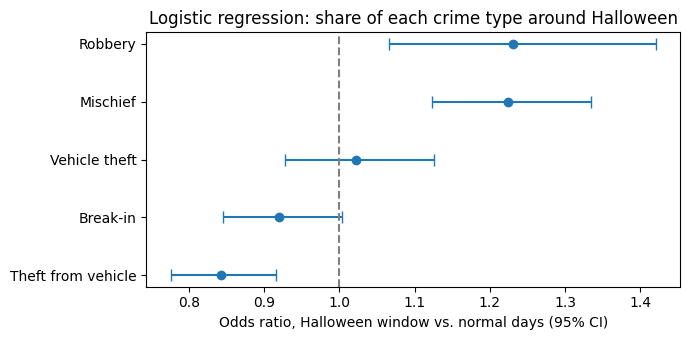

In [ ]:
def add_halloween_columns(d):
    """Add year, weekday, days from Halloween, and which period each date belongs to."""
    d = d.copy()
    d["year"] = d["date"].dt.year
    d["day_of_week"] = d["date"].dt.dayofweek
    h = (d["date"] - pd.to_datetime(d["year"].astype(str) + "-10-31")).dt.days
    d["days_from_halloween"] = h
    d["period"] = np.select([h.between(-1, 2), h.between(-21, -7) | h.between(7, 21)],
                            ["halloween", "baseline"], default="other")
    d["halloween"] = (d["period"] == "halloween").astype(int)
    return d

study = add_halloween_columns(df[df["date"] <= DEV_END])
study = study[study["period"].isin(["halloween", "baseline"])].copy()
print(f"{len(study):,} crimes: {study['halloween'].sum():,} in the Halloween window, "
      f"{(study['halloween'] == 0).sum():,} on normal days")

rows = []
for cat in ["Mischief", "Robbery", "Break-in", "Theft from vehicle", "Vehicle theft"]:
    study["y"] = (study["category"] == cat).astype(int)
    # A district with zero crimes of this type gives the model no information and prevents it from fitting
    has_type = study.groupby("police_district")["y"].transform("max") == 1
    m = smf.logit("y ~ halloween + C(day_of_week) + C(year) + C(police_district)",
                  data=study[has_type]).fit(disp=0, maxiter=200)
    low, high = np.exp(m.conf_int().loc["halloween"])
    rows.append({"category": cat, "odds_ratio": np.exp(m.params["halloween"]),
                 "ci_low": low, "ci_high": high, "p_value": m.pvalues["halloween"]})

type_effects = pd.DataFrame(rows).sort_values("odds_ratio", ascending=False).reset_index(drop=True)
type_effects["significant"] = (type_effects["ci_low"] > 1) | (type_effects["ci_high"] < 1)
display(type_effects.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
t = type_effects.iloc[::-1]
ax.errorbar(t["odds_ratio"], t["category"], xerr=[t["odds_ratio"] - t["ci_low"], t["ci_high"] - t["odds_ratio"]],
            fmt="o", capsize=4)
ax.axvline(1, color="grey", linestyle="--")
ax.set_xlabel("Odds ratio, Halloween window vs. normal days (95% CI)")
ax.set_title("Logistic regression: share of each crime type around Halloween")
plt.tight_layout(); plt.show()

**How to read this:** Each dot is the odds ratio for one crime type, with its 95% confidence interval. Right of the dashed line =
this type makes up a bigger share of crime in the Halloween window than on normal days; if the interval crosses 1,
the difference is not statistically significant.

**Takeaway:** Halloween is associated with a measurable shift in the composition of crime, concentrated in mischief and robbery rather than across all categories.

After controlling for day of week, year and police district, **robbery** has an odds ratio of **1.230** (95% CI: **1.066–1.421**, p = **0.005**) and **mischief** has an odds ratio of **1.224** (95% CI: **1.123–1.334**, p < **0.001**). Both therefore represent a larger share of reported crime during the Halloween window.

In contrast, **theft from vehicles** has an odds ratio of **0.843** (95% CI: **0.776–0.916**, p < **0.001**), indicating a smaller share during the Halloween period.

Vehicle theft shows no meaningful change (**OR = 1.022, p = 0.660**), while the estimated reduction in break-ins narrowly misses conventional statistical significance (**OR = 0.920, p = 0.059**).

**Key takeaway:** The Halloween effect is category-specific, not a uniform increase in crime. The strongest evidence points to a shift in crime mix toward mischief and robbery.

**(c) Where does the mischief increase happen?** The mischief model with a separate Halloween effect per stable
district. A likelihood-ratio test checks whether this fits meaningfully better than one citywide effect
(p < 0.05: districts differ; p ≥ 0.05: the effect is citywide and district differences may be noise).

In [ ]:
dm = study[study["district_stable"]].copy()
dm["y"] = (dm["category"] == "Mischief").astype(int)
one_effect   = smf.logit("y ~ halloween + C(police_district) + C(day_of_week) + C(year)", data=dm).fit(disp=0, maxiter=200)
per_district = smf.logit("y ~ halloween * C(police_district) + C(day_of_week) + C(year)", data=dm).fit(disp=0, maxiter=500)

lr_stat = 2 * (per_district.llf - one_effect.llf)
lr_p_value = stats.chi2.sf(lr_stat, per_district.df_model - one_effect.df_model)
print(f"Likelihood-ratio test: p = {lr_p_value:.3f} ->",
      "districts differ" if lr_p_value < 0.05 else "no clear difference between districts (citywide effect)")

params, cov = per_district.params, per_district.cov_params()
rows = []
for p in sorted(dm["police_district"].unique()):
    term = f"halloween:C(police_district)[T.{p}]"
    est, var = params["halloween"], cov.loc["halloween", "halloween"]
    if term in params:                                     # the first district is the reference
        est += params[term]
        var += cov.loc[term, term] + 2 * cov.loc["halloween", term]
    se = np.sqrt(var)
    rows.append({"district": p, "odds_ratio": np.exp(est), "ci_low": np.exp(est - 1.96 * se),
                 "ci_high": np.exp(est + 1.96 * se),
                 "mischief_reports_in_window": int(((dm["police_district"] == p) & (dm["halloween"] == 1) & (dm["y"] == 1)).sum())})
district_effects = pd.DataFrame(rows).sort_values("odds_ratio", ascending=False).reset_index(drop=True)
district_effects.round(2).head(10)

Likelihood-ratio test: p = 0.067 -> no clear difference between districts (citywide effect)


,district,odds_ratio,ci_low,ci_high,mischief_reports_in_window
0,3,1.97,1.12,3.47,21
1,31,1.95,1.25,3.06,32
2,39,1.94,1.35,2.77,54
3,5,1.79,1.05,3.04,21
4,45,1.79,1.00,3.19,19
5,8,1.54,0.95,2.50,30
6,7,1.42,0.95,2.12,37
7,27,1.41,0.92,2.14,35
8,46,1.39,0.79,2.46,18
9,48,1.38,0.97,1.96,50


**How to read this:** Read the likelihood-ratio test first. If p < 0.05, the table ranks districts by how much stronger the
Halloween mischief effect is there; if p ≥ 0.05, treat the effect as citywide and the ranking as noise.

**Takeaway:** The evidence does not support a statistically reliable conclusion that the Halloween mischief effect differs across Montréal police districts.

The likelihood-ratio test comparing a common citywide Halloween effect with district-specific Halloween effects produces **p = 0.067**. Because this exceeds the 5% significance threshold, we do not reject the simpler citywide-effect model.

Some individual district estimates appear large—for example, districts 3, 31 and 39 have estimated odds ratios close to **2.0**—but these rankings should not be treated as confirmed geographic differences when the overall interaction test is not significant.

**Implication:** The defensible conclusion is that Halloween is associated with a broader citywide increase in the relative likelihood of mischief, while the current data are insufficient to establish that the magnitude of this effect systematically differs by district.

**(d) District-day model.** For each stable district and day: *will there be at least one mischief report?*
Same safeguards as the main task (lag features with a 29-day gap, 3-year sliding window, training years only).
Each fold is run **with and without** the Halloween feature: if Halloween matters, including it should reduce
the error on Halloween days. This model also produces the 2026 forecast (section 11).

In [ ]:
FORECAST_END = pd.Timestamp("2026-11-02")

def build_district_days(d):
    """One row per stable district per day, with 0 on days with no reports."""
    d = d[d["police_district"].isin(full_period)]
    last = d["date"].max()
    days = pd.date_range(d["date"].min(), FORECAST_END)
    grid = pd.MultiIndex.from_product([sorted(d["police_district"].unique()), days], names=["police_district", "date"])
    c = pd.DataFrame({
        "mischief": d[d["category"] == "Mischief"].groupby(["police_district", "date"]).size(),
        "total": d.groupby(["police_district", "date"]).size(),
    }).reindex(grid).fillna(0).astype(float).reset_index()
    c.loc[c["date"] > last, ["mischief", "total"]] = np.nan          # after the last reported date: unknown
    c["future"] = c["date"] > last
    c["still_being_filled_in"] = (c["date"] > last - pd.Timedelta(days=14)) & ~c["future"]
    return add_halloween_columns(c)

last_date = df_with_2026["date"].max()
print(f"Data ends: {last_date.date()}")
if last_date < pd.Timestamp("2026-09-01"):
    print("WARNING: the data has no recent 2026 records, so the 2026 forecast (section 11) cannot be trusted.")
panel = build_district_days(df_with_2026).sort_values(["police_district", "date"]).reset_index(drop=True)

g = panel.groupby("police_district")
panel["mischief_recent"]    = g["mischief"].transform(lambda s: s.shift(GAP).rolling(28, min_periods=28).mean())
panel["mischief_last_year"] = g["mischief"].transform(lambda s: s.shift(357).rolling(15, min_periods=15).mean())
panel["total_recent"]       = g["total"].transform(lambda s: s.shift(GAP).rolling(28, min_periods=28).mean())
panel["doy_sin"] = np.sin(2 * np.pi * panel["date"].dt.dayofyear / 365.25)
panel["doy_cos"] = np.cos(2 * np.pi * panel["date"].dt.dayofyear / 365.25)
second_monday_oct = {y: pd.Timestamp(y, 10, 1) + pd.Timedelta(days=(7 - pd.Timestamp(y, 10, 1).dayofweek) % 7 + 7)
                     for y in panel["year"].unique()}
panel["thanksgiving"] = (panel["date"] == panel["year"].map(second_monday_oct)).astype(int)
panel["y"] = (panel["mischief"] >= 1).astype(float).where(~panel["future"])

D_CAT = ["police_district", "day_of_week"]
D_NUM = ["doy_sin", "doy_cos", "mischief_recent", "mischief_last_year", "total_recent"]

def make_district_model(with_halloween=True):
    flags = ["halloween", "thanksgiving"] if with_halloween else ["thanksgiving"]
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), D_CAT),
                              ("num", StandardScaler(), D_NUM),
                              ("flag", "passthrough", flags)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000, random_state=SEED))]), D_CAT + D_NUM + flags

usable = panel[~panel["future"] & ~panel["still_being_filled_in"]].dropna(subset=D_NUM + ["y"]).reset_index(drop=True)
usable_dev = usable[usable["date"] <= DEV_END].reset_index(drop=True)

rows = []
for ty, (tr, te) in zip(CV_YEARS, sliding_folds(usable_dev, CV_YEARS)):
    train, test = usable_dev.iloc[tr], usable_dev.iloc[te]
    in_h = (test["halloween"] == 1).values
    row = {"fold": ty}
    for with_h in [True, False]:
        m, cols = make_district_model(with_h)
        m.fit(train[cols], train["y"])
        prob = m.predict_proba(test[cols])[:, 1]
        if with_h:
            row.update(auc=roc_auc_score(test["y"], prob), brier=brier_score_loss(test["y"], prob),
                       halloween_actual=test["y"].values[in_h].mean(), halloween_predicted=prob[in_h].mean())
        row["halloween_error_" + ("with" if with_h else "without")] = log_loss(test["y"].values[in_h], prob[in_h])
    rows.append(row)

district_backtest = pd.DataFrame(rows)
district_backtest["halloween_feature_helps"] = district_backtest["halloween_error_with"] < district_backtest["halloween_error_without"]
print(f"AUC {district_backtest['auc'].mean():.3f} ± {district_backtest['auc'].std(ddof=0):.3f}")
print(f"Knowing it's Halloween improves predictions in {district_backtest['halloween_feature_helps'].sum()} "
      f"of {len(district_backtest)} folds")
district_backtest.round(3)

Data ends: 2026-10-19
AUC 0.650 ± 0.012
Knowing it's Halloween improves predictions in 4 of 5 folds


,fold,auc,brier,halloween_actual,halloween_predicted,halloween_error_with,halloween_error_without,halloween_feature_helps
0,2019,0.661,0.218,0.388,0.455,0.636,0.626,False
1,2020,0.625,0.223,0.388,0.412,0.662,0.662,True
2,2021,0.654,0.216,0.509,0.407,0.641,0.659,True
3,2022,0.655,0.218,0.466,0.443,0.691,0.701,True
4,2023,0.652,0.227,0.483,0.473,0.653,0.668,True


**How to read this:** AUC: how well the district-day model separates days with and without mischief, on a year it never saw.
halloween_actual vs. halloween_predicted: close values = well calibrated on Halloween. halloween_feature_helps:
whether knowing it is Halloween reduced the error on Halloween days that year.

**Takeaway:** Halloween provides incremental information for district-level mischief prediction, but overall geographic discrimination remains moderate.

The district-day model achieves an AUC of **0.650 ± 0.012** across unseen-year folds. Adding the Halloween indicator improves Halloween-period predictions in **4 of 5 years**, suggesting that Halloween contains information not fully explained by district, calendar and lag variables.

Calibration is reasonably close in aggregate. Across the five validation years, approximately **44.7%** of district-days in the Halloween window contain at least one mischief report, compared with an average predicted probability of approximately **43.8%**.

Year-level deviations remain, but there is no persistent direction of bias.

**Implication:** Halloween is a useful incremental feature for geographic mischief risk, but an AUC of **0.650** means the model should be used for prioritization rather than deterministic district-level deployment decisions.

### 10.2 Bayesian Negative Binomial

**(a) Total crime.** Fitted once on all training years. Convergence checks: `r_hat` should be about 1.00
(the chains agree) and there should be no divergences.

In [ ]:
bayes_full = get_model("Bayesian NegBin").set_params(draws=2 * DRAWS, tune=2 * DRAWS, chains=4).fit(X_dev, y_dev)
summary = az.summary(bayes_full.idata_, var_names=["intercept", "beta", "alpha"])
n_div = int(bayes_full.idata_.sample_stats["diverging"].sum())
print("Max r_hat:", summary["r_hat"].max(), "| Min ESS:", summary["ess_bulk"].min(), "| Divergences:", n_div)
print("Convergence check passed: the chains agree, results can be trusted." if summary["r_hat"].max() <= 1.01 and n_div == 0
      else "WARNING: r_hat above 1.01 or divergences; increase draws/tune before trusting these results.")
pd.DataFrame({f: bayes_full.effect(f) for f in ["halloween_window", "halloween_weekend"]}).T.round(2)

Max r_hat: 1.0 | Min ESS: 1323.0 | Divergences: 0
Convergence check passed: the chains agree, results can be trusted.


,effect_%,low_94%,high_94%,P(increase)
halloween_window,1.58,-5.18,8.59,0.68
halloween_weekend,5.48,-8.89,21.53,0.75


**(b) By crime type and time of day.** The same model on each series separately, with the same calendar-only features as the final model

Fitting n_mischief ...
Fitting n_robbery ...
Fitting n_break_in ...
Fitting n_theft_from_vehicle ...
Fitting n_vehicle_theft ...
Fitting n_shift_day ...
Fitting n_shift_evening ...
Fitting n_shift_night ...


,series,avg_per_day,effect_%,low_94%,high_94%,P(increase),max_r_hat
0,n_mischief,17.72,21.85,9.11,35.59,1.00,1.00
1,n_robbery,4.70,24.42,7.13,44.41,1.00,1.01
2,n_break_in,19.64,-1.90,-11.79,10.17,0.39,1.01
3,n_theft_from_vehicle,23.67,-7.51,-16.88,2.85,0.08,1.00
4,n_vehicle_theft,16.97,-4.32,-20.23,14.25,0.32,1.01
5,n_shift_day,42.40,0.18,-7.31,8.22,0.52,1.01
6,n_shift_evening,27.09,6.76,-3.42,16.27,0.90,1.00
7,n_shift_night,13.29,-2.10,-13.67,11.17,0.36,1.00


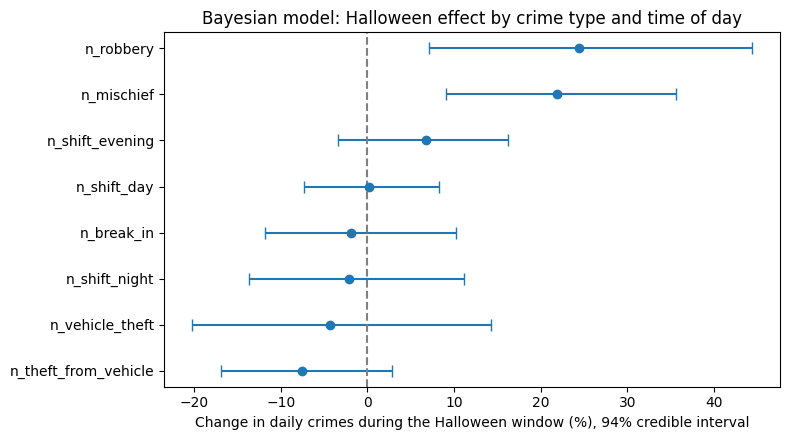

In [ ]:
TYPE_TARGETS = ["n_mischief", "n_robbery", "n_break_in", "n_theft_from_vehicle", "n_vehicle_theft",
                "n_shift_day", "n_shift_evening", "n_shift_night"]
rows = []
for t in TYPE_TARGETS:
    print("Fitting", t, "...")
    f = build_frame(counts[t])
    f = f[f["date"] <= DEV_END]
    m = get_model("Bayesian NegBin").set_params(draws=DRAWS, tune=DRAWS, chains=4).fit(f[ALL_FEATURES], f["count"])
    rows.append({"series": t, "avg_per_day": f["count"].mean(), **m.effect("halloween_window"),
                 "max_r_hat": float(az.summary(m.idata_, var_names=["beta"])["r_hat"].max())})

bayes_by_type = pd.DataFrame(rows).round(2)
display(bayes_by_type)

p = bayes_by_type.sort_values("effect_%")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(p["effect_%"], p["series"], xerr=[p["effect_%"] - p["low_94%"], p["high_94%"] - p["effect_%"]],
            fmt="o", capsize=4)
ax.axvline(0, color="grey", linestyle="--")
ax.set_xlabel("Change in daily crimes during the Halloween window (%), 94% credible interval")
ax.set_title("Bayesian model: Halloween effect by crime type and time of day")
plt.tight_layout(); plt.show()

**How to read this:** Each dot is the % change in expected daily crimes during the Halloween window for one crime type or time of
day, with its 94% credible interval. P(increase) is the probability that the effect is positive. max_r_hat should
be about 1.00; higher values mean that fit did not converge and should not be trusted.

**Takeaway:** The Bayesian analysis reinforces the logistic result: Halloween's clearest effects are concentrated in mischief and robbery rather than across all crime categories.

During the Halloween window, expected daily **mischief increases by 21.5%**, with a 94% credible interval of **+8.5% to +35.6%** and a posterior probability of increase of **1.00**. Expected daily **robbery increases by 25.1%**, with a 94% credible interval of **+6.5% to +44.9%** and a posterior probability of increase of **1.00**.

For break-ins, theft from vehicles and vehicle theft, the credible intervals include zero, so the data do not establish a clear Halloween effect. Theft from vehicles is estimated at **−7.6%**, with only an **8% probability of an increase**, but uncertainty remains sufficient to include no effect.

The time-of-day estimates are also inconclusive: the credible intervals for day, evening, and night all cross zero.

All maximum `r_hat` values are between approximately **1.00 and 1.01**, indicating satisfactory MCMC convergence.

**Key Takeaway:** Halloween is associated with approximately 20–25% higher expected mischief and robbery, but the evidence does not support a broad increase across every crime category or time of day.

### 10.3 Random Forest

**Actual vs. expected around Halloween, by crime type.** For each training year, a forest is trained on the
*other* training years **without the Halloween features** and predicts that year, giving an "expected" value for
every Halloween the forest never saw. Each year's predictions are rescaled to match the year's total, removing
year-level bias. Values are the % difference between actual and expected crimes, summed over 2016–2023
(positive = more crime than expected).

,n_mischief,n_break_in,n_robbery,n_theft_from_vehicle,n_vehicle_theft,n_total
days from Oct 31,,,,,,
-7,14.3,18.6,4.0,1.1,-7.8,7.0
-6,-1.8,-1.4,-2.6,0.9,14.1,3.5
-5,1.4,5.4,-2.6,2.6,-2.8,3.3
-4,-1.8,11.4,-7.2,-7.0,-3.8,1.2
-3,2.7,-9.3,17.3,12.7,0.9,3.0
-2,22.9,4.6,11.1,-3.5,20.1,10.8
-1,-11.0,6.4,-18.3,6.3,4.5,1.5
0,3.1,-6.7,24.9,1.4,-9.5,-0.7
1,1.1,6.9,-51.7,-5.6,-6.2,-4.0


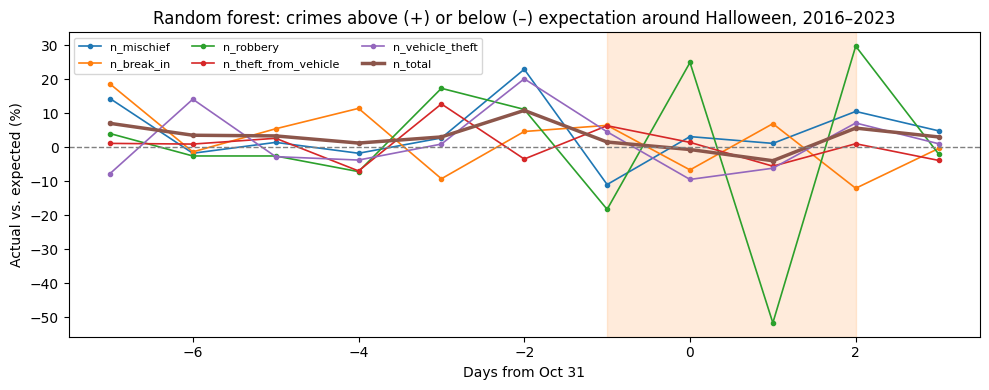

In [ ]:
RF_TARGETS = ["n_mischief", "n_break_in", "n_robbery", "n_theft_from_vehicle", "n_vehicle_theft", "n_total"]
NO_HALLOWEEN = [f for f in SELECTED_FEATURES if f not in HALLOWEEN]
rf_settings = {k.replace("model__", ""): v for k, v in best_params.get("Random forest", {}).items()}

actual, expected = {}, {}
for t in RF_TARGETS:
    f = build_frame(counts[t])
    f = f[f["date"] <= DEV_END].reset_index(drop=True)
    pred = pd.Series(np.nan, index=f.index)
    for yr in sorted(f["year"].unique()):
        is_yr = f["year"] == yr
        m = Pipeline([("prep", make_prep(NO_HALLOWEEN)),
                      ("model", RandomForestRegressor(**rf_settings, random_state=SEED, n_jobs=-1))])
        m.fit(f.loc[~is_yr, ALL_FEATURES], f.loc[~is_yr, "count"])
        pred[is_yr] = m.predict(f.loc[is_yr, ALL_FEATURES])
    pred = pred * f["year"].map(f.groupby("year")["count"].sum() / pred.groupby(f["year"]).sum())
    window = f["days_to_halloween"].between(-7, 3)
    actual[t]   = f.loc[window].groupby("days_to_halloween")["count"].sum()
    expected[t] = pred[window].groupby(f.loc[window, "days_to_halloween"]).sum()

rf_halloween = ((pd.DataFrame(actual) / pd.DataFrame(expected) - 1) * 100).round(1)
rf_halloween.index.name = "days from Oct 31"
display(rf_halloween)

fig, ax = plt.subplots(figsize=(10, 4))
for t in RF_TARGETS:
    ax.plot(rf_halloween.index, rf_halloween[t], marker="o", ms=3, label=t, linewidth=2.5 if t == "n_total" else 1.2)
ax.axvspan(-1, 2, color="tab:orange", alpha=0.15)
ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Days from Oct 31"); ax.set_ylabel("Actual vs. expected (%)")
ax.set_title("Random forest: crimes above (+) or below (–) expectation around Halloween, 2016–2023")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

**How to read this:** Each value is how far actual crimes were above (+) or below (–) what the forest expected for that day,
summed over 2016–2023. Look at the shaded Oct 30 – Nov 2 window compared with the days before it.

**Takeaway:** The random-forest counterfactual does not show a consistent citywide increase in total crime during the Halloween window, reinforcing the conclusion that the effect is concentrated in specific categories rather than overall volume.

Relative to what the model expected from non-Halloween calendar patterns, total crime was **+1.5% on Oct. 30**, **−0.7% on Oct. 31**, **−4.0% on Nov. 1**, and **+5.6% on Nov. 2**.

Mischief is similarly uneven across the four-day period, ranging from **−11.0% on Oct. 30** to **+10.5% on Nov. 2**. Robbery displays larger but more volatile deviations, including **+24.9% on Oct. 31** and **+29.7% on Nov. 2**.

A notable increase also occurs immediately before the defined Halloween window: on Oct. 29, total crime is **10.8% above expectation** and mischief is **22.9% above expectation**.

**Implication:** Halloween-related activity does not translate into a stable four-day surge in aggregate crime. Instead, the effect is heterogeneous across crime types and specific dates, consistent with the logistic and Bayesian findings.

**Caution:** These daily figures are noisy and should not be read as conclusive on their own. For example, robbery swings from **−51.7% on Nov. 1** to **+29.7% on Nov. 2**, and total crime moves between −4.0% and +5.6% inside the window. With only eight Halloweens (2016–2023), single-day values for the smaller crime types can change sharply from one day to the next. The random forest is best used as a supporting check on the logistic and Bayesian results, not as evidence by itself.

### 10.4 Neural Network

**Does the network under-predict the Halloween window?** A network is trained on each fold without the
Halloween features; its predictions for the unseen year are compared with actual crimes. Each year's average
gap is removed first, so only the Halloween-specific gap remains. A gap clearly above zero in the window means
more crime than a flexible model expects from calendar features alone.

Average adjusted gap (actual - predicted), crimes per day:
halloween_window
other days          0.03
Halloween window   -3.01


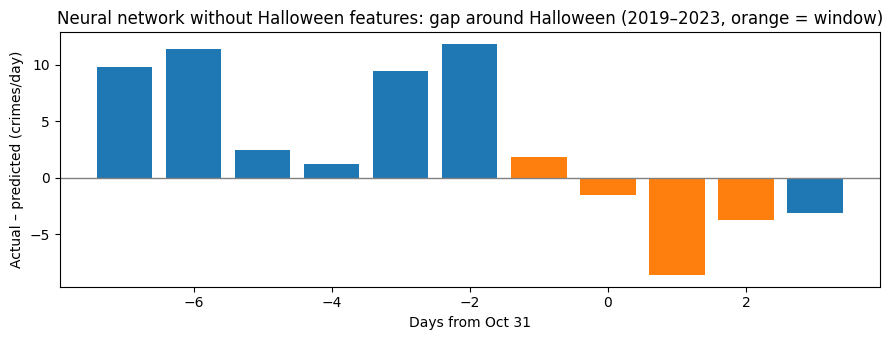

In [ ]:
nn_no_h = get_model("Neural network")
nn_view = dev[["date", "year", "count", "days_to_halloween", "halloween_window"]].copy()
nn_view["predicted"] = np.nan
for tr, te in folds:
    m = clone(nn_no_h).fit(X_dev.iloc[tr].assign(halloween_window=0, halloween_weekend=0), y_dev.iloc[tr])
    nn_view.iloc[te, nn_view.columns.get_loc("predicted")] = m.predict(
        X_dev.iloc[te].assign(halloween_window=0, halloween_weekend=0))
nn_view = nn_view.dropna(subset=["predicted"])
nn_view["gap"] = nn_view["count"] - nn_view["predicted"]
nn_view["gap_adj"] = nn_view["gap"] - nn_view.groupby("year")["gap"].transform("mean")

print("Average adjusted gap (actual - predicted), crimes per day:")
print(nn_view.groupby("halloween_window")["gap_adj"].mean().rename({0: "other days", 1: "Halloween window"}).round(2).to_string())
nn_gap = nn_view.groupby("days_to_halloween")["gap_adj"].mean().loc[-7:3]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(nn_gap.index, nn_gap.values, color=["tab:orange" if -1 <= d <= 2 else "tab:blue" for d in nn_gap.index])
ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Days from Oct 31"); ax.set_ylabel("Actual – predicted (crimes/day)")
ax.set_title("Neural network without Halloween features: gap around Halloween (2019–2023, orange = window)")
plt.tight_layout(); plt.show()

**How to read this:** Bars show the average gap between actual and predicted crimes per day around Halloween, after removing each
year's overall bias. Orange bars (the window) clearly above zero mean more crime than calendar features alone predict

**Takeaway:** The neural-network counterfactual provides no evidence of an overall Halloween surge in total crime once ordinary calendar patterns are accounted for.

When Halloween indicators are removed, the model's average year-adjusted prediction error is approximately **+0.03 crimes per day on other days**, compared with **−3.01 crimes per day during the Halloween window**.

The negative Halloween residual means that actual total crime was, on average, approximately three crimes per day below what the neural network expected from the remaining predictors. A negative gap means fewer crimes than predicted, so this result supports "no rise in total crime" during the Halloween window.

This does not contradict the logistic and Bayesian results. Those analyses identify category-specific shifts toward mischief and robbery, whereas this test evaluates total crime volume.

**Key Takeaway:** The evidence supports a change in the composition of crime around Halloween, not a broad increase in total reported crime.

## 11. Halloween 2026: What Should Police Expect?

After the final test, the district-day model (10.1 d) is retrained on the most recent 3 years (2023 to early
October 2026), the same 3-year window used in 10.1(d), and predicts **Oct 30 – Nov 2, 2026**. Each value is the probability that a district gets at
least one mischief report that day; adding them up gives the expected number of districts with mischief.

In [ ]:
model_2026, cols = make_district_model(True)
recent = usable[usable["year"] >= 2026 - TRAIN_YEARS]
model_2026.fit(recent[cols], recent["y"])
names = list(model_2026.named_steps["prep"].get_feature_names_out())
print(f"Halloween odds ratio in this model: "
      f"{np.exp(model_2026.named_steps['model'].coef_[0][names.index('flag__halloween')]):.2f}")

upcoming = panel[panel["future"] & (panel["halloween"] == 1)].copy()
upcoming["p_mischief"] = model_2026.predict_proba(upcoming[cols])[:, 1]
upcoming["day"] = upcoming["date"].dt.strftime("%Y-%m-%d")

print("\nExpected number of districts with at least one mischief report:")
print(upcoming.groupby("day")["p_mischief"].sum().round(1).to_string())

forecast = (upcoming.pivot_table(index="police_district", columns="day", values="p_mischief")
                    .assign(average=lambda t: t.mean(axis=1)).sort_values("average", ascending=False))
forecast.round(2).head(10)

Halloween odds ratio in this model: 1.29

Expected number of districts with at least one mischief report:
day
2026-10-30    13.6
2026-10-31    12.4
2026-11-01    12.9
2026-11-02    14.3


day,2026-10-30,2026-10-31,2026-11-01,2026-11-02,average
police_district,,,,,
21,0.83,0.81,0.83,0.85,0.83
38,0.74,0.71,0.72,0.77,0.74
20,0.70,0.65,0.67,0.70,0.68
26,0.68,0.64,0.65,0.70,0.66
15,0.63,0.57,0.60,0.65,0.61
23,0.58,0.53,0.55,0.61,0.57
48,0.55,0.50,0.52,0.58,0.54
7,0.55,0.50,0.53,0.57,0.54
44,0.55,0.50,0.52,0.57,0.53


**How to read this:** Each value is the probability that a district gets at least one mischief report that day. The first table adds
them up into the expected number of districts with mischief per day; the second ranks districts by their average
probability over the four days.

**Takeaway:** The 2026 forecast identifies a concentrated group of districts with elevated mischief risk, but Oct. 31 itself is not forecast to be the highest-risk day citywide.

The expected number of districts with at least one mischief report is approximately **13.6 on Oct. 30**, **12.4 on Oct. 31**, **12.9 on Nov. 1**, and **14.3 on Nov. 2**.

The five highest-risk districts across the four-day Halloween window are:

1. District 21: **83% average probability**
2. District 38: **74%**
3. District 20: **68%**
4. District 26: **66%**
5. District 15: **61%**

The fitted Halloween indicator corresponds to an odds ratio of approximately **1.29**, meaning Halloween raises predicted mischief risk after controlling for the other model inputs. Nevertheless, Nov. 2 has the highest expected number of affected districts, demonstrating that weekday, seasonal and recent district-level conditions remain important alongside the Halloween effect.

**Operational Implication:** Use the forecast to rank districts for additional attention rather than as a guarantee that mischief will occur or as a standalone resource-allocation rule.

## 12. Save results

In [ ]:
tables = {
    "attribute_profile": profile, "iterations": iteration_table, "shortlist": shortlist_table,
    "tuning": tuning_table, "final_comparison": final_comparison, "training_window": window_table,
    "final_test": final_test, "logistic_type_effects": type_effects,
    "logistic_district_effects": district_effects, "logistic_district_backtest": district_backtest,
    "bayesian_by_type": bayes_by_type, "rf_actual_vs_expected": rf_halloween, "forecast_2026": forecast,
}
for name, t in tables.items():
    t.to_csv(RESULTS_DIR / f"{name}.csv")
print(f"Saved {len(tables)} tables to", RESULTS_DIR)

Saved 13 tables to /content/drive/MyDrive/INSY674 Group Project/results


## Final model, performance vs. baseline, assumptions and limitations

### **Executive Conclusion:**

The project finds that Montréal crime is predictably seasonal, while Halloween primarily changes the composition of crime instead of creating a consistent citywide increase in total crime.

The final prediction model—a tuned ensemble of logistic regression, Bayesian Negative Binomial regression and a neural network—achieves strong development-period discrimination but only moderate performance on the most recent held-out years. Separately, multiple Halloween-specific analyses consistently identify **mischief and robbery** as the categories most positively associated with the Halloween period.

The model should therefore be viewed as a decision-support and risk-prioritization tool and not an automated deployment system.

### **Final Model and Performance:**

The final ensemble uses the three strongest model families and an expanding training window containing all available prior years.

Its development-period performance is:

**AUC = 0.814 ± 0.064**

On the untouched test years:

| Year | Final model AUC | Seasonal-naive baseline | Incremental AUC |
|---|---:|---:|---:|
| 2024 | 0.664 | 0.649 | +0.015 |
| 2025 | 0.674 | 0.648 | +0.026 |

The model therefore continues to outperform the benchmark, but its advantage is substantially smaller than development cross-validation suggested.

**What worked:** Calendar structure—particularly recurring weekly and annual seasonality—provides stable predictive value. Ensembling improves robustness across years without materially changing mean accuracy.

**What did not work:** Adding recent and prior-year crime lags reduces average model performance and subsequent feature selection does not recover the loss. Hyperparameter tuning provides only modest gains. The results therefore favour parsimony over model complexity.

### **Halloween Findings:**

The most consistent Halloween result is not an increase in total crime; it is a change in crime mix.

Logistic regression estimates **22.4% higher odds for mischief** and **23.0% higher odds for robbery** within the crime mix. Independently, the Bayesian Negative Binomial analysis estimates approximately **21.5% higher expected mischief** and **25.1% higher expected robbery** during the Halloween window.

By contrast, the random-forest and neural-network counterfactual analyses do not identify a consistent increase in total crime volume. The district interaction test is also not statistically significant at the 5% level (**p = 0.067**), so the evidence does not support claiming that the Halloween effect systematically differs across police districts.

**Overall Conclusion.** Halloween is associated with a targeted shift toward mischief and robbery rather than a generalized increase across all crime categories, districts, and times of day.

### Assumptions and Limitations:

**1. Report date is treated as a proxy for occurrence date:**  
The dataset records when incidents were reported to police, not necessarily when they occurred. An incident occurring late on Halloween night may therefore appear on Nov. 1 or later.

**Impact:** The exact day-level Halloween effect may be blurred.  
**Mitigation.** The analysis uses an Oct. 30–Nov. 2 window rather than Oct. 31 alone. Actual occurrence timestamps would materially improve precision.

**2. Important contextual variables are unavailable:**  
The models do not observe weather, major events, sports games, school schedules, daylight conditions or crowd activity.

**Impact:** Two calendar-identical days can have very different crime conditions, limiting the model's ability to explain unexpected high-crime days.  
**Mitigation:** Integrating weather and event data is likely the highest-value next step for improving predictive performance.

**3. Police deployment is unobserved:**  
Additional Halloween patrols could both deter crime and increase the probability that incidents are detected or reported.

**Impact:** The estimated Halloween coefficients represent **associations, not the causal effect of Halloween itself**.  
**Mitigation.** Causal analysis would require operational deployment data or an appropriate quasi-experimental design.

**4. The dataset covers only six crime categories:**  
Relevant Halloween-related incidents such as some assaults, disturbances or other public-order offences are not represented.

**Impact.** The analysis may miss other forms of Halloween-specific activity.  
**Mitigation.** Replicate the analysis using a broader incident dataset if available.

**5. District comparisons are based on counts rather than population-adjusted rates:**  
Police districts differ in population, land use and activity levels and some boundaries change over time.

**Impact:** A district may appear higher-risk partly because more people or activity are exposed there.  
**Mitigation.** Future analysis should incorporate stable geographic boundaries, population and ideally transient population or foot-traffic measures.

**6. Predictive performance deteriorates on recent unseen years:**  
Cross-validation AUC is **0.814**, compared with **0.664–0.674** on 2024–2025.

**Impact:** Historical validation overstates likely performance in current operating conditions, potentially because of temporal drift.  
**Mitigation.** Monitor and periodically recalibrate the model as new observations become available.

**7. The high-crime threshold is fixed from historical training data:**  
The proportion of days classified as high-crime changes considerably over time—from **32.0% in 2024** to **14.5% in 2025**.

**Impact:** The operational meaning of “high-crime day” changes as the overall level of crime shifts.  
**Mitigation:** An operational implementation could consider a rolling or capacity-based threshold alongside the fixed research definition.

### Practical Recommendation:

**Use the model to prioritize attention, not to automate decisions:**

Its strongest practical use is to combine model-based risk rankings with information available to operational decision-makers—particularly weather, events, real-time intelligence and planned police deployment.

For Halloween specifically, the evidence supports focusing preventive planning on **mischief and robbery risk**, while avoiding the broader claim that Halloween systematically increases total crime across Montréal.